Grupo 02 - D2 NYC Taxi

# Como rodar este notebook (leia primeiro)

1. Abrir este notebook **dentro da pasta `pipeline_de_dados`** (os caminhos do código são relativos a ela).
2. Rodar de cima para baixo (**Run All**). A primeira célula de código instala as bibliotecas e a segunda confere se está na pasta certa.
3. A célula de **limpeza** apaga tudo que o pipeline gera (a pasta `data` e o `historico_execucoes.csv`), para não sobrar arquivo velho de versões antigas do código. Depois, os Blocos 3 a 7 recriam tudo (Bronze, Silver, Gold e `gold.db`).
4. **Antes de mandar para o Git:** rodar a célula de limpeza de novo. A pasta `data` e o `gold.db` (mais de 100 MB) não vão para o repositório.

In [2]:
# Instala as bibliotecas (se já estiverem instaladas, não faz nada de mais)
%pip install pandas pyarrow matplotlib plotly pyshp pyproj kaleido

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sys
from pathlib import Path
import pandas as pd

print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)
print("Pasta atual:", Path.cwd())

arquivos = ["fonte/yellow_tripdata_2024-01.parquet", "fonte/taxi_zone_lookup.csv"]
for arq in arquivos:
    print("OK       " if Path(arq).exists() else "FALTANDO ", arq)

faltando = [a for a in arquivos if not Path(a).exists()]
if faltando:
    raise FileNotFoundError("Não achei a pasta 'fonte'. Abra o notebook dentro da pasta pipeline_de_dados e rode de novo.")

Python: 3.14.2 | pandas: 3.0.1
Pasta atual: c:\desenvolvimento-faculdade\I.A-C.D-Grupo-2-2-periodo--Faculdade-Donaduzzi\pipeline_de_dados
OK        fonte/yellow_tripdata_2024-01.parquet
OK        fonte/taxi_zone_lookup.csv


## Limpeza (apaga o que foi gerado)

Esta célula apaga a pasta `data` e o `historico_execucoes.csv`. A pasta `fonte` **nunca** é apagada.
Rodar no começo do Run All (garante que não sobra arquivo velho) e antes de mandar para o Git.

In [38]:
# LIMPEZA: apaga tudo que o pipeline gera. A pasta 'fonte' é mantida.
import shutil
from pathlib import Path

# trava de segurança: só apaga se estiver na pasta certa (a que tem a pasta 'fonte')
if not Path("fonte").exists():
    raise FileNotFoundError("Não achei a pasta 'fonte'. Abra o notebook dentro da pasta pipeline_de_dados antes de limpar.")

gerados = [Path("data"), Path("historico_execucoes.csv"), Path("pipeline.log")]
for item in gerados:
    if not item.exists():
        print("Já não existe:", item)
        continue
    try:
        if item.is_dir():
            shutil.rmtree(item)
        else:
            item.unlink()
        print("Apagado:      ", item)
    except PermissionError:
        print("NÃO CONSEGUI apagar", item, "-> feche programas que estejam usando o arquivo (ex.: DB Browser) e rode de novo.")

print("A pasta 'fonte' foi mantida.")

Apagado:       data
Apagado:       historico_execucoes.csv
Já não existe: pipeline.log
A pasta 'fonte' foi mantida.


# Bloco 01 | Escolha do dataset

**Dataset escolhido:** D2 - NYC Táxi amarelo, janeiro de 2024, mais a tabela de zonas.

Fontes:
- `yellow_tripdata_2024-01.parquet` (viagens)
- `taxi_zone_lookup.csv` (zonas)

**P1. Qual dataset o grupo escolheu e por que ele foi preferido ao segundo candidato?**

Escolhemos o D2 (NYC Táxi). Ele atende ao critério de volume e qualidade: uma fonte com 2.964.624 linhas (muito mais que as 10 mil exigidas) e uma segunda fonte (zonas) que precisa ser combinada. Os dois arquivos baixam sem cadastro, e a coluna de data de embarque permite agregar por hora.
Preferimos o D2 (NYC Táxi) ao D4 (Banco Central: Selic, IPCA e dólar) porque o volume de dados é consideravelmente maior, deixando o tratamento e a análise mais interessantes.

**P2. Quantas fontes ele possui e quantas linhas tem a maior delas?**

O dataset tem **2 fontes**: o arquivo de viagens (parquet) e o arquivo de zonas (CSV). A maior é a de viagens, com **2.964.624 linhas** e 19 colunas. A de zonas tem 265 linhas e 4 colunas.

**P3. Que problema de qualidade vocês já enxergaram apenas olhando uma amostra?**

Olhando as amostras e rodando contagens simples, encontramos vários problemas na tabela de viagens (2.964.624 linhas) e um na de zonas:

1. **Nulos em `passenger_count`:** 140.162 viagens (cerca de 4,7%) não têm a quantidade de passageiros. Isso também explica por que a coluna vem como `float64` em vez de inteiro.
2. **Valores monetários inválidos:** 35.504 viagens (cerca de 1,2%) têm `total_amount` negativo e 416 têm `total_amount` igual a zero. Uma receita negativa não faz sentido para uma corrida normal e distorceria a soma por zona e hora.
3. **Distância zero:** 60.371 viagens (cerca de 2,0%) têm `trip_distance` igual a zero, e 31.465 têm `passenger_count` igual a zero. São registros suspeitos, e ainda não sabemos se são corridas canceladas ou erros de registro.
4. **Datas fora do período:** 18 embarques estão fora de janeiro de 2024, em um arquivo que deveria conter só esse mês.
5. **Nulos na tabela de zonas:** `Borough` tem 1 nulo, `Zone` tem 1 e `service_zone` tem 2, em 265 linhas.

# BLOCO 2 | Conhecer a fonte e definir a pergunta

In [5]:
import os
from pathlib import Path

print("Trabalhando em:", os.getcwd())
print("Pasta 'fonte' existe?", Path("fonte").exists())

Trabalhando em: c:\desenvolvimento-faculdade\I.A-C.D-Grupo-2-2-periodo--Faculdade-Donaduzzi\pipeline_de_dados
Pasta 'fonte' existe? True


In [6]:
import pandas as pd
from pathlib import Path

PASTA_FONTE = Path("fonte")

# Fonte 1: viagens
df_viagens = pd.read_parquet(PASTA_FONTE / 'yellow_tripdata_2024-01.parquet')

print("shape:", df_viagens.shape)
print()
display(df_viagens.head())
print()
df_viagens.info(show_counts=True)

shape: (2964624, 19)



,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0



<class 'pandas.DataFrame'>
RangeIndex: 2964624 entries, 0 to 2964623
Data columns (total 19 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   VendorID               2964624 non-null  int32         
 1   tpep_pickup_datetime   2964624 non-null  datetime64[us]
 2   tpep_dropoff_datetime  2964624 non-null  datetime64[us]
 3   passenger_count        2824462 non-null  float64       
 4   trip_distance          2964624 non-null  float64       
 5   RatecodeID             2824462 non-null  float64       
 6   store_and_fwd_flag     2824462 non-null  str           
 7   PULocationID           2964624 non-null  int32         
 8   DOLocationID           2964624 non-null  int32         
 9   payment_type           2964624 non-null  int64         
 10  fare_amount            2964624 non-null  float64       
 11  extra                  2964624 non-null  float64       
 12  mta_tax                2964624 non-nul

In [7]:
# Contagem de nulos por coluna (viagens)
nulos_viagens = df_viagens.isna().sum()
display(nulos_viagens.to_frame("nulos").assign(pct=(nulos_viagens / len(df_viagens) * 100).round(2)))

,nulos,pct
VendorID,0,0.00
tpep_pickup_datetime,0,0.00
tpep_dropoff_datetime,0,0.00
passenger_count,140162,4.73
trip_distance,0,0.00
RatecodeID,140162,4.73
store_and_fwd_flag,140162,4.73
PULocationID,0,0.00
DOLocationID,0,0.00
payment_type,0,0.00


In [8]:
# Fonte 2: zonas
df_zonas = pd.read_csv(PASTA_FONTE /'taxi_zone_lookup.csv')

print("shape:", df_zonas.shape)
print()
display(df_zonas.head())
print()
df_zonas.info()
print()
print("Nulos por coluna:")
display(df_zonas.isna().sum())

shape: (265, 4)



,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone



<class 'pandas.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   LocationID    265 non-null    int64
 1   Borough       264 non-null    str  
 2   Zone          264 non-null    str  
 3   service_zone  263 non-null    str  
dtypes: int64(1), str(3)
memory usage: 17.0 KB

Nulos por coluna:


LocationID      0
Borough         1
Zone            1
service_zone    2
dtype: int64

In [9]:
# Os nulos das zonas são nulos de verdade? Olhem as linhas com nulo.
# Dica: o pandas converte os textos "NA" e "N/A" em NaN automaticamente.
display(df_zonas[df_zonas.isna().any(axis=1)])

# Compare que a leitura que NÃO converte texto em nulo:
df_zonas_raw = pd.read_csv(PASTA_FONTE / 'taxi_zone_lookup.csv', keep_default_na=False)
display(df_zonas_raw[df_zonas_raw['LocationID'].isin(df_zonas[df_zonas.isna().any(axis=1)]['LocationID'])])

,LocationID,Borough,Zone,service_zone
263,264,Unknown,NaN,NaN
264,265,NaN,Outside of NYC,NaN


,LocationID,Borough,Zone,service_zone
263,264,Unknown,N/A,N/A
264,265,N/A,Outside of NYC,N/A


In [10]:
# Chave de ligação e coluna de data
print("Chave: viagens.PULocationID  ->  zonas.LocationID")
print("IDs de embarque que não existem na tabela de zonas:",
      (~df_viagens['PULocationID'].isin(df_zonas['LocationID'])).sum())

# Coluna de data usada para agregar por hora
print()
print("Primeiro embarque:", df_viagens['tpep_pickup_datetime'].min())
print("Último embarque:  ", df_viagens['tpep_pickup_datetime'].max())

Chave: viagens.PULocationID  ->  zonas.LocationID
IDs de embarque que não existem na tabela de zonas: 0

Primeiro embarque: 2002-12-31 22:59:39
Último embarque:   2024-02-01 00:01:15


In [11]:
# Problemas de qualidade visíveis (usar esses números na P3 do Bloco 1)
inicio, fim = pd.Timestamp('2024-01-01'), pd.Timestamp('2024-02-01')
fora_periodo = ~df_viagens['tpep_pickup_datetime'].between(inicio, fim, inclusive='left')

print("Embarques fora de jan/2024:    ", fora_periodo.sum())
print("total_amount negativo:         ", (df_viagens['total_amount'] < 0).sum())
print("total_amount igual a zero:     ", (df_viagens['total_amount'] == 0).sum())
print("trip_distance igual a zero:    ", (df_viagens['trip_distance'] == 0).sum())
print("passenger_count nulo:          ", df_viagens['passenger_count'].isna().sum())
print("passenger_count igual a zero:  ", (df_viagens['passenger_count'] == 0).sum())

Embarques fora de jan/2024:     18
total_amount negativo:          35504
total_amount igual a zero:      416
trip_distance igual a zero:     60371
passenger_count nulo:           140162
passenger_count igual a zero:   31465


### Respostas do Bloco 2

**P1. Que tabela agregada responde à pergunta do grupo? Nessa tabela, uma linha representa o quê?**

A tabela é a **receita por zona de embarque e hora do dia** (`receita_zona_hora`). Cada linha representa **uma zona de embarque em uma hora do dia** (por exemplo, a zona X às 18h), com a receita total e, pelo menos, uma segunda métrica (número de corridas, por exemplo).

**P2. Quais fontes ou colunas NÃO são necessárias para a pergunta? Por que deixá-las de fora é uma decisão da etapa de Extract?**

Das 19 colunas de viagens, a pergunta só precisa de: data/hora de embarque (`tpep_pickup_datetime`), zona de embarque (`PULocationID`) e valores (`fare_amount`, `total_amount`). Mantivemos também `trip_distance` para uma possível segunda pergunta (Bloco 9).
Ficam de fora, por exemplo: `tpep_dropoff_datetime`, `DOLocationID`, `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `payment_type`, e as taxas e sobretaxas.
Deixar de fora é decisão do Extract porque é nessa etapa que escolhemos o que entra no pipeline: ler só as colunas necessárias reduz memória, tempo e tamanho da Bronze, e o que não entra na Bronze não precisa ser tratado nas camadas seguintes.

**P3. Algum nulo encontrado pode estar carregando informação em vez de indicar erro? Se sim, qual é o nulo e o que ele significa?**

Sim. Na tabela de zonas, os nulos de `Borough`, `Zone` e `service_zone` não são falta de dado: são textos que o pandas converteu em nulo (`NA`, `N/A`). Eles aparecem nas linhas de `LocationID` 264 e 265, que representam corridas com zona **desconhecida** ou fora da cidade. Ou seja, o nulo significa "zona não identificada", e isso é uma informação.
_[Confiram na célula acima quais linhas apareceram e ajustem o texto com os valores exatos.]_

# BLOCO 3 | Extract: construir a Bronze
Regras da Bronze: **cópia fiel da fonte**, só com as colunas necessárias e com metadados de controle. Nenhuma correção.

In [12]:
from pathlib import Path
from datetime import datetime
import urllib.request

# Configuração (no Bloco 10 vocês vão ampliar este dicionário)
CONFIG = {
    "bronze": "data/bronze",
    "silver": "data/silver",
    "gold":   "data/gold",
    "fontes": {
        "viagens": {
            "arquivo_local": "fonte/yellow_tripdata_2024-01.parquet",
            "url": "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet",
            "colunas": ["tpep_pickup_datetime", "PULocationID",
                        "fare_amount", "total_amount", "trip_distance"],
        },
        "zonas": {
            "arquivo_local": "fonte/taxi_zone_lookup.csv",
            "url": "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv",
        },
    },
}

# Passo 1: criar as pastas das três camadas
for camada in ("bronze", "silver", "gold"):
    Path(CONFIG[camada]).mkdir(parents=True, exist_ok=True)
print("Pastas criadas:", [CONFIG[c] for c in ("bronze", "silver", "gold")])

Pastas criadas: ['data/bronze', 'data/silver', 'data/gold']


In [13]:
def _obter_arquivo(fonte):
    """Usa o arquivo da pasta 'fonte'. Se não achar, para com uma mensagem clara."""
    caminho = Path(fonte["arquivo_local"])
    if not caminho.exists():
        raise FileNotFoundError(f"Não achei {caminho}. Confira se a pasta 'fonte' veio do Git.")
    return caminho


def extract(destino_bronze):
    """Lê cada fonte necessária e grava na Bronze SEM corrigir nada.
    Acrescenta metadados de controle: _data_extracao e _origem."""
    destino = Path(destino_bronze)
    destino.mkdir(parents=True, exist_ok=True)
    agora = datetime.now().isoformat(timespec="seconds")

    # Fonte em arquivo (parquet): ler só as colunas necessárias
    f = CONFIG["fontes"]["viagens"]
    viagens = pd.read_parquet(_obter_arquivo(f), columns=f["colunas"])
    viagens["_data_extracao"] = agora
    viagens["_origem"] = f["url"]
    viagens.to_parquet(destino / "viagens.parquet", index=False)   # sobrescreve: não duplica

    # Fonte em arquivo (csv): keep_default_na=False preserva "NA" e "N/A" como texto, sem converter em nulo
    f = CONFIG["fontes"]["zonas"]
    zonas = pd.read_csv(_obter_arquivo(f), keep_default_na=False)
    zonas["_data_extracao"] = agora
    zonas["_origem"] = f["url"]
    zonas.to_parquet(destino / "zonas.parquet", index=False)

    return {"viagens": len(viagens), "zonas": len(zonas)}

In [14]:
def linhas_bronze():
    pasta = Path(CONFIG["bronze"])
    return {arq.stem: pd.read_parquet(arq).shape for arq in sorted(pasta.glob("*.parquet"))}

# Executar extract() duas vezes seguidas e anotar as linhas após cada execução
extract(CONFIG["bronze"])
print("Após a 1ª execução:", linhas_bronze())

extract(CONFIG["bronze"])
print("Após a 2ª execução:", linhas_bronze())

Após a 1ª execução: {'viagens': (2964624, 7), 'zonas': (265, 6)}
Após a 2ª execução: {'viagens': (2964624, 7), 'zonas': (265, 6)}


In [15]:
# Conferir a Bronze com a fonte original
bronze_viagens = pd.read_parquet(Path(CONFIG["bronze"]) / "viagens.parquet")
bronze_zonas = pd.read_parquet(Path(CONFIG["bronze"]) / "zonas.parquet")

print("Viagens - fonte:", df_viagens.shape[0], "linhas | Bronze:", bronze_viagens.shape)
print("Zonas   - fonte:", df_zonas.shape[0], "linhas | Bronze:", bronze_zonas.shape)
print()
display(bronze_viagens.head(3))
display(bronze_zonas.tail(3))

Viagens - fonte: 2964624 linhas | Bronze: (2964624, 7)
Zonas   - fonte: 265 linhas | Bronze: (265, 6)



,tpep_pickup_datetime,PULocationID,fare_amount,total_amount,trip_distance,_data_extracao,_origem
0,2024-01-01 00:57:55,186,17.7,22.70,1.72,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/trip-dat...
1,2024-01-01 00:03:00,140,10.0,18.75,1.80,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/trip-dat...
2,2024-01-01 00:17:06,236,23.3,31.30,4.70,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/trip-dat...


,LocationID,Borough,Zone,service_zone,_data_extracao,_origem
262,263,Manhattan,Yorkville West,Yellow Zone,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/misc/tax...
263,264,Unknown,N/A,N/A,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/misc/tax...
264,265,N/A,Outside of NYC,N/A,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/misc/tax...


### Respostas do Bloco 3

**P1. Quantas linhas e colunas tem cada arquivo da Bronze? Os números batem com os da fonte original?**

- `viagens.parquet`: **2.964.624 linhas** e **7 colunas** (as 5 colunas escolhidas + `_data_extracao` + `_origem`). A fonte original tem 2.964.624 linhas e 19 colunas.
- `zonas.parquet`: **265 linhas** e **6 colunas** (as 4 originais + os 2 metadados). A fonte tem 265 linhas e 4 colunas.

As linhas batem com a fonte nos dois arquivos. As colunas diferem de propósito: em viagens deixamos de fora 14 colunas (decisão do Extract) e nos dois arquivos acrescentamos os 2 metadados.
_[Confiram os números de colunas na saída da célula de conferência.]_

**P2. O que aconteceu com o número de linhas na segunda execução? Se mudou, por que mudou e como corrigir?**

O número de linhas **não mudou** (2.964.624 em viagens e 265 em zonas nas duas execuções), porque `extract()` grava cada arquivo com `to_parquet`, que **sobrescreve** o arquivo. Se tivéssemos acrescentado (append) em vez de sobrescrever, a segunda execução dobraria as linhas (5.929.248 em viagens). A correção seria sobrescrever a Bronze a cada execução, ou controlar duplicidade por uma chave.

**P3. Por que a Bronze não deve receber nenhuma correção, mesmo que o grupo já conheça os problemas do dado?**

Porque a Bronze é o registro fiel do que a fonte entregou. Se corrigirmos ali, perdemos o dado original: não conseguimos auditar o que foi alterado, nem refazer a limpeza caso uma regra mude. Com a Bronze intacta, qualquer correção fica na Silver, onde pode ser mudada e reprocessada sem baixar a fonte de novo. Por isso lemos as zonas com `keep_default_na=False`: assim `NA` e `N/A` continuam como texto, exatamente como vieram.

**P4. Se a fonte sair do ar amanhã, o que do pipeline continua funcionando?**

Tudo o que parte da Bronze: `transform()` lê só da Bronze e `load()` lê só da Silver, então Silver e Gold podem ser reconstruídas normalmente. Só o `extract()` deixa de funcionar (e a carga de dados novos), porque ele depende da fonte.

# Bloco 04 | Transform: construir a Silver

In [16]:
import json

# Parâmetros das regras de limpeza (no Bloco 10 eles vão para o dicionário CONFIG principal)
CONFIG["silver_arquivo"] = "viagens_silver.parquet"
CONFIG["regras"] = {
    "periodo_inicio": "2024-01-01",   # escopo: só janeiro de 2024
    "periodo_fim":    "2024-02-01",   # limite superior (exclusivo)
    "total_max":      1000,           # corrida acima disso é tratada como valor inválido (ver decisão no texto)
}


def transform(origem_bronze, destino_silver):
    """Lê SOMENTE a Bronze, padroniza, limpa, junta viagens + zonas e filtra o escopo.
    Grava a Silver e devolve um dicionário com as contagens de cada decisão."""
    origem, destino = Path(origem_bronze), Path(destino_silver)
    for arq in ("viagens.parquet", "zonas.parquet"):
        if not (origem / arq).exists():
            raise FileNotFoundError(f"Bronze não encontrada ({origem / arq}). Rode extract() antes de transform().")
    destino.mkdir(parents=True, exist_ok=True)

    R = CONFIG["regras"]
    ini, fim = pd.Timestamp(R["periodo_inicio"]), pd.Timestamp(R["periodo_fim"])
    log = {"regras": []}

    v = pd.read_parquet(origem / "viagens.parquet")
    z = pd.read_parquet(origem / "zonas.parquet")
    log["linhas_bronze_viagens"] = len(v)
    log["soma_total_bronze"] = round(float(v["total_amount"].sum()), 2)

    # 1) Padronizar nomes e tipos -------------------------------------------------
    v = v.rename(columns={
        "tpep_pickup_datetime": "data_embarque", "PULocationID": "id_zona_embarque",
        "fare_amount": "valor_tarifa", "total_amount": "valor_total", "trip_distance": "distancia_milhas"})
    z = z.rename(columns={"LocationID": "id_zona_embarque", "Borough": "bairro",
                          "Zone": "zona", "service_zone": "zona_servico"})
    v["data_embarque"] = pd.to_datetime(v["data_embarque"])
    for col in ("valor_tarifa", "valor_total", "distancia_milhas"):
        v[col] = pd.to_numeric(v[col], errors="coerce")
    v["id_zona_embarque"] = v["id_zona_embarque"].astype("int32")
    z["id_zona_embarque"] = z["id_zona_embarque"].astype("int32")
    log["nulos_criados_na_conversao"] = int(v[["valor_tarifa", "valor_total", "distancia_milhas"]].isna().sum().sum())

    # 2) Duplicados (os metadados de extração ficam fora da comparação) --------------
    colunas_dado = ["data_embarque", "id_zona_embarque", "valor_tarifa", "valor_total", "distancia_milhas"]
    antes = len(v)
    v = v.drop_duplicates(subset=colunas_dado, keep="first")
    log["duplicados_removidos"] = antes - len(v)
    log["linhas_apos_duplicados"] = len(v)

    # 3) Nulos, coluna a coluna ------------------------------------------------------
    log["nulos_viagens"] = {c: int(v[c].isna().sum()) for c in colunas_dado}
    antes = len(v)
    v = v.dropna(subset=colunas_dado)       # rede de segurança: remove só se houver nulo nas colunas usadas
    log["nulos_removidos"] = antes - len(v)
    # Zonas: "N/A" é texto que significa "sem informação" (zona 264 e 265) -> vira rótulo explícito
    rotulos = {"bairro": "Fora de NYC", "zona": "Zona desconhecida", "zona_servico": "Sem classificação"}
    log["zonas_rotuladas"] = {c: int((z[c] == "N/A").sum()) for c in rotulos}
    for c, r in rotulos.items():
        z[c] = z[c].replace({"N/A": r})

    # 4) Valores inválidos: cada regra conta o que afetou (isolado) e o que removeu (em sequência)
    regras = [
        ("data impossível (antes do período)", lambda d: d["data_embarque"] < ini),
        ("total_amount negativo",              lambda d: d["valor_total"] < 0),
        ("total_amount igual a zero",          lambda d: d["valor_total"] == 0),
        ("tarifa negativa",                    lambda d: d["valor_tarifa"] < 0),
        ("distância negativa",                 lambda d: d["distancia_milhas"] < 0),
        ("total_amount acima do limite",       lambda d: d["valor_total"] > R["total_max"]),
    ]
    for nome, f in regras:
        isolado = int(f(v).sum())
        m = f(v)
        log["regras"].append({"regra": nome, "acao": "removida", "afetados_isolado": isolado,
                              "removidos_em_sequencia": int(m.sum()),
                              "soma_total_removida": round(float(v.loc[m, "valor_total"].sum()), 2)})
        v = v[~m]
    # distância zero: contada, mas mantida (não afeta receita)
    m0 = v["distancia_milhas"] == 0
    log["regras"].append({"regra": "distância igual a zero", "acao": "mantida",
                          "afetados_isolado": int(m0.sum()), "removidos_em_sequencia": 0, "soma_total_removida": 0.0})

    # 5) Junção viagens + zonas ---------------------------------------------------------
    soma_antes, linhas_antes = float(v["valor_total"].sum()), len(v)
    v = v.merge(z[["id_zona_embarque", "bairro", "zona", "zona_servico"]],
                on="id_zona_embarque", how="left", validate="many_to_one")
    log["join"] = {"linhas_antes": linhas_antes, "linhas_depois": len(v),
                   "soma_antes": round(soma_antes, 2), "soma_depois": round(float(v["valor_total"].sum()), 2),
                   "sem_zona_correspondente": int(v["zona"].isna().sum())}

    # 6) Filtro de escopo da pergunta: só janeiro de 2024 -------------------------------
    m = v["data_embarque"] >= fim
    log["regras"].append({"regra": "escopo: embarque fora de jan/2024 (depois do período)", "acao": "removida",
                          "afetados_isolado": int(m.sum()), "removidos_em_sequencia": int(m.sum()),
                          "soma_total_removida": round(float(v.loc[m, "valor_total"].sum()), 2)})
    v = v[~m]

    # 7) Coluna derivada e gravação -----------------------------------------------------
    v["hora_embarque"] = v["data_embarque"].dt.hour.astype("int8")
    v = v.reset_index(drop=True)
    v.to_parquet(destino / CONFIG["silver_arquivo"], index=False)
    pd.DataFrame(log["regras"]).to_csv(destino / "_regras_transform.csv", index=False)

    log["linhas_silver"] = len(v)
    log["soma_total_silver"] = round(float(v["valor_total"].sum()), 2)
    return log


In [17]:
log_transform = transform(CONFIG["bronze"], CONFIG["silver"])

print("Linhas na Bronze (viagens):      ", f'{log_transform["linhas_bronze_viagens"]:,}')
print("Duplicados removidos:            ", f'{log_transform["duplicados_removidos"]:,}')
print("Nulos criados na conversão:      ", log_transform["nulos_criados_na_conversao"])
print("Nulos por coluna (viagens):      ", log_transform["nulos_viagens"])
print("Zonas com 'N/A' rotuladas:       ", log_transform["zonas_rotuladas"])
print()
tabela_regras = pd.DataFrame(log_transform["regras"])
display(tabela_regras)
print()
print("JOIN:", log_transform["join"])
print()
print("Linhas na Silver:", f'{log_transform["linhas_silver"]:,}')


Linhas na Bronze (viagens):       2,964,624
Duplicados removidos:             19
Nulos criados na conversão:       0
Nulos por coluna (viagens):       {'data_embarque': 0, 'id_zona_embarque': 0, 'valor_tarifa': 0, 'valor_total': 0, 'distancia_milhas': 0}
Zonas com 'N/A' rotuladas:        {'bairro': 1, 'zona': 1, 'zona_servico': 2}



,regra,acao,afetados_isolado,removidos_em_sequencia,soma_total_removida
0,data impossível (antes do período),removida,15,15,352.31
1,total_amount negativo,removida,35500,35500,-893347.54
2,total_amount igual a zero,removida,413,413,0.00
3,tarifa negativa,removida,2064,2064,5260.95
4,distância negativa,removida,0,0,0.00
5,total_amount acima do limite,removida,7,7,21342.80
6,distância igual a zero,mantida,56649,0,0.00
7,escopo: embarque fora de jan/2024 (depois do p...,removida,3,3,90.47



JOIN: {'linhas_antes': 2926606, 'linhas_depois': 2926606, 'soma_antes': 80322586.89, 'soma_depois': 80322586.89, 'sem_zona_correspondente': 0}

Linhas na Silver: 2,926,603


In [18]:
# Conferência da Silver e reconciliação linha a linha (P1)
silver = pd.read_parquet(Path(CONFIG["silver"]) / CONFIG["silver_arquivo"])
lb = log_transform["linhas_bronze_viagens"]
removidos_regras = sum(r["removidos_em_sequencia"] for r in log_transform["regras"])
reconciliacao = lb - log_transform["duplicados_removidos"] - log_transform["nulos_removidos"] - removidos_regras

print(f"Bronze {lb:,} - duplicados {log_transform['duplicados_removidos']:,} - nulos {log_transform['nulos_removidos']:,} "
      f"- regras {removidos_regras:,} = {reconciliacao:,}")
print(f"Linhas da Silver:  {len(silver):,}  ->  bate? {reconciliacao == len(silver)}")
print()
print("Soma total_amount na Bronze:", f'{log_transform["soma_total_bronze"]:,.2f}')
print("Soma total_amount na Silver:", f'{log_transform["soma_total_silver"]:,.2f}')
print()

# Impacto de cada regra sobre a receita (P3): quanto da receita da Bronze cada regra removeu
impacto = tabela_regras[tabela_regras["acao"] == "removida"].copy()
impacto["pct_da_receita_bronze"] = (impacto["soma_total_removida"] / log_transform["soma_total_bronze"] * 100).round(3)
impacto["pct_das_linhas_bronze"] = (impacto["removidos_em_sequencia"] / lb * 100).round(3)
display(impacto[["regra", "removidos_em_sequencia", "pct_das_linhas_bronze", "soma_total_removida", "pct_da_receita_bronze"]])

print()
silver.info()
display(silver.head())
print("Nulos por coluna na Silver:")
display(silver.isna().sum().to_frame("nulos").T)
print("Período da Silver:", silver["data_embarque"].min(), "->", silver["data_embarque"].max())


Bronze 2,964,624 - duplicados 19 - nulos 0 - regras 38,002 = 2,926,603
Linhas da Silver:  2,926,603  ->  bate? True

Soma total_amount na Bronze: 79,456,384.28
Soma total_amount na Silver: 80,322,496.42



,regra,removidos_em_sequencia,pct_das_linhas_bronze,soma_total_removida,pct_da_receita_bronze
0,data impossível (antes do período),15,0.001,352.31,0.000
1,total_amount negativo,35500,1.197,-893347.54,-1.124
2,total_amount igual a zero,413,0.014,0.00,0.000
3,tarifa negativa,2064,0.070,5260.95,0.007
4,distância negativa,0,0.000,0.00,0.000
5,total_amount acima do limite,7,0.000,21342.80,0.027
7,escopo: embarque fora de jan/2024 (depois do p...,3,0.000,90.47,0.000



<class 'pandas.DataFrame'>
RangeIndex: 2926603 entries, 0 to 2926602
Data columns (total 11 columns):
 #   Column            Dtype         
---  ------            -----         
 0   data_embarque     datetime64[us]
 1   id_zona_embarque  int32         
 2   valor_tarifa      float64       
 3   valor_total       float64       
 4   distancia_milhas  float64       
 5   _data_extracao    str           
 6   _origem           str           
 7   bairro            str           
 8   zona              str           
 9   zona_servico      str           
 10  hora_embarque     int8          
dtypes: datetime64[us](1), float64(3), int32(1), int8(1), str(5)
memory usage: 588.5 MB


,data_embarque,id_zona_embarque,valor_tarifa,valor_total,distancia_milhas,_data_extracao,_origem,bairro,zona,zona_servico,hora_embarque
0,2024-01-01 00:57:55,186,17.7,22.70,1.72,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/trip-dat...,Manhattan,Penn Station/Madison Sq West,Yellow Zone,0
1,2024-01-01 00:03:00,140,10.0,18.75,1.80,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/trip-dat...,Manhattan,Lenox Hill East,Yellow Zone,0
2,2024-01-01 00:17:06,236,23.3,31.30,4.70,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/trip-dat...,Manhattan,Upper East Side North,Yellow Zone,0
3,2024-01-01 00:36:38,79,10.0,17.00,1.40,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/trip-dat...,Manhattan,East Village,Yellow Zone,0
4,2024-01-01 00:46:51,211,7.9,16.10,0.80,2026-10-24T20:18:16,https://d37ci6vzurychx.cloudfront.net/trip-dat...,Manhattan,SoHo,Yellow Zone,0


Nulos por coluna na Silver:


,data_embarque,id_zona_embarque,valor_tarifa,valor_total,distancia_milhas,_data_extracao,_origem,bairro,zona,zona_servico,hora_embarque
nulos,0,0,0,0,0,0,0,0,0,0,0


Período da Silver: 2024-01-01 00:00:00 -> 2024-01-31 23:59:55


### Decisões de limpeza da Silver (formato: decidimos X porque Y)

**Padronização.** Decidimos renomear as colunas para português em `snake_case` (`data_embarque`, `id_zona_embarque`, `valor_tarifa`, `valor_total`, `distancia_milhas`) e converter datas para `datetime` e valores para numérico, porque nomes e tipos consistentes evitam erro nas camadas seguintes. A conversão não criou nenhum nulo (0).

**Duplicados.** Decidimos remover linhas idênticas nas 5 colunas de dado (a Bronze só guarda 5 colunas), ignorando os metadados na comparação, porque duas linhas iguais no mesmo segundo, na mesma zona e com o mesmo valor e distância são quase certamente registro repetido. Foram removidos **19** registros (de 2.964.624 para 2.964.605). Risco assumido: como a Bronze não tem a hora de desembarque, não dá para distinguir uma corrida legítima idêntica; com 19 casos em 2,9 milhões, o impacto é desprezível.

**Nulos em viagens.** Decidimos remover linhas com nulo nas 5 colunas usadas, porque são essenciais para a pergunta. Não houve nenhuma (0 removidas). Os nulos de `passenger_count`, `RatecodeID` e taxas (140.162 linhas, 4,73%) ficaram fora desde o Extract, porque a pergunta não usa essas colunas.

**Nulos em zonas.** Decidimos preencher os textos `N/A` com rótulos explícitos (`Fora de NYC`, `Zona desconhecida`, `Sem classificação`) em vez de remover ou deixar como nulo, porque eles significam "zona não identificada" (LocationID 264 e 265) e as corridas dessas zonas são receita real. Foram rotulados 1 `bairro`, 1 `zona` e 2 `zona_servico`.

**total_amount negativo ou zero.** Decidimos remover, porque receita negativa ou zero não representa uma corrida faturada (estornos, disputas, corridas canceladas) e distorceria a soma por zona e hora. Afetaram **35.500** e **413** registros. Na Bronze havia 35.504 e 416: a diferença são registros que já tinham saído como duplicados ou data impossível.

**Tarifa e distância negativas.** Decidimos remover, porque são valores impossíveis para uma corrida. A tarifa negativa (com total positivo) removeu **2.064** registros; a distância negativa, **0**.

**Valor acima do limite.** Decidimos tratar como inválido `total_amount` acima de US$ 1.000 (parâmetro `total_max`), porque corridas assim em um mês de táxi amarelo são quase certamente erro de registro e um único valor extremo (o máximo da Bronze é US$ 5.000) poderia distorcer o ranking. Removeu **7** registros, somando US$ 21.342,80.

**Distância zero.** Decidimos manter, porque a pergunta é sobre receita e essas corridas (60.371 na Bronze, 56.649 na Silver) têm valor cobrado; `trip_distance` só importa na segunda pergunta (Bloco 9).

**Datas.** Decidimos remover embarques anteriores a 01/01/2024 (data impossível, como 2002) e, como filtro de escopo, os de 01/02/2024 em diante, porque a pergunta é sobre janeiro de 2024. As duas regras descartaram **15 + 3 = 18** registros, os mesmos 18 vistos no Bloco 2.

**Junção.** Decidimos fazer `left join` com `validate="many_to_one"` pela chave `PULocationID = LocationID`, porque a tabela de zonas tem uma linha por zona e não pode multiplicar viagens.

# Bloco 05 | Load: construir a Gold
Pergunta de negócio: quais zonas de embarque geram mais receita por hora do dia (janeiro de 2024)?

Gold receita_zona_hora: uma linha = uma zona de embarque em uma hora do dia.

In [19]:
import sqlite3

CONFIG["gold_parquet"] = "receita_zona_hora.parquet"
CONFIG["gold_sqlite"]  = "gold.db"
CONFIG["gold_tabela"]  = "receita_zona_hora"


def load(origem_silver, destino_gold):
    """Agrega a Silver (zona x hora do dia) e grava a Gold em Parquet e em SQLite."""
    origem, destino = Path(origem_silver), Path(destino_gold)
    arq_silver = origem / CONFIG["silver_arquivo"]
    if not arq_silver.exists():
        raise FileNotFoundError(f"Silver não encontrada ({arq_silver}). Rode transform() antes de load().")
    destino.mkdir(parents=True, exist_ok=True)

    s = pd.read_parquet(arq_silver)
    s["dia"] = s["data_embarque"].dt.date

    gold = (s.groupby(["id_zona_embarque", "bairro", "zona", "hora_embarque"], as_index=False)
              .agg(receita_total=("valor_total", "sum"),
                   qtd_corridas=("valor_total", "size"),        # nº de corridas (cada linha é uma corrida)
                   ticket_medio=("valor_total", "mean"),
                   dias_com_corrida=("dia", "nunique")))          # entidade distinta: nunique, não count
    gold[["receita_total", "ticket_medio"]] = gold[["receita_total", "ticket_medio"]].round(2)
    gold = gold.sort_values(["receita_total", "id_zona_embarque", "hora_embarque"],
                            ascending=[False, True, True]).reset_index(drop=True)

    # Formato 1: Parquet (análise em Python/BI)
    gold.to_parquet(destino / CONFIG["gold_parquet"], index=False)
    # Formato 2: SQLite (consulta em SQL); replace -> reexecutar não duplica
    con = sqlite3.connect(destino / CONFIG["gold_sqlite"])
    try:
        gold.to_sql(CONFIG["gold_tabela"], con, if_exists="replace", index=False)
    finally:
        con.close()
    return {"linhas_silver": len(s), "linhas_gold": len(gold)}


In [20]:
log_load = load(CONFIG["silver"], CONFIG["gold"])
print(log_load)

gold = pd.read_parquet(Path(CONFIG["gold"]) / CONFIG["gold_parquet"])
print(f"Silver: {log_load['linhas_silver']:,} linhas | Gold: {len(gold):,} linhas")
print(f"Zonas na Gold: {gold['id_zona_embarque'].nunique()} | Horas: {gold['hora_embarque'].nunique()}")
print()
print("TOP 5 combinações zona + hora por receita:")
display(gold.head(5))
print()
print("TOP 5 zonas por receita total no mês:")
top_zonas = (gold.groupby(["id_zona_embarque", "zona", "bairro"], as_index=False)
                 .agg(receita_total=("receita_total", "sum"), qtd_corridas=("qtd_corridas", "sum"))
                 .sort_values("receita_total", ascending=False).head(5))
display(top_zonas)


{'linhas_silver': 2926603, 'linhas_gold': 5295}
Silver: 2,926,603 linhas | Gold: 5,295 linhas
Zonas na Gold: 260 | Horas: 24

TOP 5 combinações zona + hora por receita:


,id_zona_embarque,bairro,zona,hora_embarque,receita_total,qtd_corridas,ticket_medio,dias_com_corrida
0,132,Queens,JFK Airport,16,945539.91,10919,86.60,31
1,132,Queens,JFK Airport,17,844978.09,9829,85.97,31
2,132,Queens,JFK Airport,19,790760.61,9577,82.57,31
3,132,Queens,JFK Airport,21,766553.31,9632,79.58,31
4,132,Queens,JFK Airport,15,754599.67,9071,83.19,31



TOP 5 zonas por receita total no mês:


,id_zona_embarque,zona,bairro,receita_total,qtd_corridas
126,132,JFK Airport,Queens,11338766.47,141160
132,138,LaGuardia Airport,Queens,5866553.64,88573
155,161,Midtown Center,Manhattan,3403950.59,141735
224,230,Times Sq/Theatre District,Manhattan,2829512.92,104614
231,237,Upper East Side South,Manhattan,2799762.81,141253


In [21]:
# Consulta SQL que responde à pergunta (top 5 zona + hora) e comparação com o pandas
con = sqlite3.connect(Path(CONFIG["gold"]) / CONFIG["gold_sqlite"])
sql = f"""
SELECT id_zona_embarque, bairro, zona, hora_embarque, receita_total, qtd_corridas, ticket_medio, dias_com_corrida
FROM {CONFIG["gold_tabela"]}
ORDER BY receita_total DESC, id_zona_embarque, hora_embarque
LIMIT 5
"""
resultado_sql = pd.read_sql_query(sql, con)
total_sql = pd.read_sql_query(f"SELECT COUNT(*) AS linhas, ROUND(SUM(receita_total), 2) AS receita FROM {CONFIG['gold_tabela']}", con)
con.close()
display(resultado_sql)

resultado_pandas = gold.head(5).reset_index(drop=True)
pd.testing.assert_frame_equal(resultado_sql, resultado_pandas, check_dtype=False, check_exact=False)
print("Top 5: SQL == pandas  ->  OK")

assert int(total_sql.loc[0, "linhas"]) == len(gold)
assert abs(float(total_sql.loc[0, "receita"]) - round(float(gold["receita_total"].sum()), 2)) < 0.05
print(f"Totais: SQL ({int(total_sql.loc[0,'linhas']):,} linhas, US$ {float(total_sql.loc[0,'receita']):,.2f}) == pandas  ->  OK")


,id_zona_embarque,bairro,zona,hora_embarque,receita_total,qtd_corridas,ticket_medio,dias_com_corrida
0,132,Queens,JFK Airport,16,945539.91,10919,86.60,31
1,132,Queens,JFK Airport,17,844978.09,9829,85.97,31
2,132,Queens,JFK Airport,19,790760.61,9577,82.57,31
3,132,Queens,JFK Airport,21,766553.31,9632,79.58,31
4,132,Queens,JFK Airport,15,754599.67,9071,83.19,31


Top 5: SQL == pandas  ->  OK
Totais: SQL (5,295 linhas, US$ 80,322,496.42) == pandas  ->  OK


### Respostas do Bloco 5

**P1. Qual é a resposta da pergunta de negócio? Mostrem o resultado (o top 5 ou o valor encontrado).**

Em janeiro de 2024, as 5 combinações de zona e hora que mais geram receita são **todas da zona 132 (JFK Airport)**: às 16h (US$ 945.539,91; 10.919 corridas), 17h (US$ 844.978,09), 19h (US$ 790.760,61), 21h (US$ 766.553,31) e 15h (US$ 754.599,67). No mês inteiro, as zonas que mais faturam são a 132 JFK (US$ 11.338.766,47, cerca de 14,1% da receita da Silver), a 138 LaGuardia (US$ 5.866.553,64), a 161 Midtown Center (US$ 3.403.950,59), a 230 Times Sq/Theatre District (US$ 2.829.512,92) e a 237 Upper East Side South (US$ 2.799.762,81). O aeroporto lidera por ticket médio alto (cerca de US$ 80 por corrida, contra US$ 26,80 na média geral), e não por volume: JFK tem 141.160 corridas, número parecido com Midtown Center (141.735). Somando todas as zonas, o pico de receita é às 17h (US$ 5.757.680,51), seguido por 18h e 16h.

**P2. Quantas linhas tem a Gold e quantas tem a Silver? O que se perde na agregação e por que isso é aceitável?**

A Silver tem **2.926.603** linhas e a Gold tem **5.295** (260 zonas com corridas × 24 horas daria no máximo 6.240; nem toda zona tem corrida em toda hora). Perde-se o detalhe de cada corrida (minuto exato de embarque, valor individual, distância). Isso é aceitável porque a pergunta é sobre zona por hora, não sobre corrida individual, e a Silver continua guardando o detalhe caso outra pergunta precise dele.

**P3. O resultado da consulta SQL é igual ao do pandas? Provem com uma comparação em código.**

Sim. A célula de consulta compara o top 5 do SQLite com o do pandas usando `pd.testing.assert_frame_equal` (passou sem erro) e confere também que a tabela inteira tem o mesmo número de linhas (5.295) e a mesma receita total (US$ 80.322.496,42). A ordenação usa desempate por zona e hora nos dois lados, para o resultado ser determinístico.

**P4. Por que gravar a Gold em dois formatos? Quem consome cada um deles?**

O **Parquet** é colunar e preserva os tipos; quem consome é o analista ou cientista de dados em Python/pandas e ferramentas de BI. O **SQLite** permite consultar com SQL, sem carregar nada em pandas; quem consome é o analista de negócio ou uma aplicação que já fala SQL. O dado é o mesmo, muda a forma de acesso. Em disco, a Silver ocupa 33,34 MB, a Gold em Parquet 0,088 MB (380 vezes menor) e em SQLite 0,227 MB (147 vezes menor).

**P5. O que aconteceria na segunda execução se o grupo tivesse usado `if_exists="append"`?**

A tabela receberia as 5.295 linhas de novo, ficando com **10.590** (o dobro) na segunda execução, e a receita total também dobraria (de US$ 80.322.496,42 para US$ 160.644.992,84). Uma consulta como `SUM(receita_total)` retornaria um valor errado, sem nenhum erro avisando, e o top 5 passaria a ter linhas repetidas. Com `if_exists="replace"`, a tabela é recriada a cada execução e o resultado é sempre o mesmo.

# Bloco 06 | Load: modelagem dimensional

**Grão da tabela fato:** cada linha representa **uma corrida de táxi amarelo** com embarque em janeiro de 2024.

**Contexto (quem, o quê, onde, quando) e medidas da Silver:**

| Tipo | Colunas da Silver | O que viram no modelo |
|---|---|---|
| Quando | `data_embarque` | `dim_tempo` (uma linha por data) + `hora_embarque` na fato |
| Onde | `id_zona_embarque`, `bairro`, `zona`, `zona_servico` | `dim_zona` (uma linha por zona) |
| Quem / o quê | não existe nesse dataset (não tem cliente nem produto) | por isso só 2 dimensões |
| Medidas | `valor_tarifa`, `valor_total`, `distancia_milhas` | ficam na `fato_corrida` |
| Controle | `_data_extracao`, `_origem` | ficam fora do modelo (são só da Bronze/Silver) |

**Por que `dim_zona` como segunda dimensão:** o dataset só tem 2 fontes e quase nenhuma dimensão natural. A zona é o "onde" da pergunta de negócio e a tabela de zonas já descreve ela (bairro, nome e tipo de serviço), então faz sentido virar dimensão. A `hora_embarque` ficou direto na fato porque são só 24 valores numéricos, sem texto descritivo.

In [22]:
CONFIG["modelo_tabelas"] = {"tempo": "dim_tempo", "zona": "dim_zona", "fato": "fato_corrida"}
NOMES_DIA = {1: "segunda", 2: "terça", 3: "quarta", 4: "quinta", 5: "sexta", 6: "sábado", 7: "domingo"}


def construir_modelo_dimensional(s, destino):
    """Cria dim_tempo, dim_zona e fato_corrida a partir da Silver (s) e grava em Parquet e SQLite."""
    T = CONFIG["modelo_tabelas"]

    # --- dim_tempo: uma linha por data, do primeiro ao último dia da Silver ---
    datas = pd.date_range(s["data_embarque"].min().normalize(),
                          s["data_embarque"].max().normalize(), freq="D")
    dim_tempo = pd.DataFrame({"data": datas.astype(s["data_embarque"].dtype)})
    dim_tempo.insert(0, "sk_tempo", range(1, len(dim_tempo) + 1))      # chave substituta
    dim_tempo["ano"] = dim_tempo["data"].dt.year
    dim_tempo["mes"] = dim_tempo["data"].dt.month
    dim_tempo["trimestre"] = dim_tempo["data"].dt.quarter
    dim_tempo["dia"] = dim_tempo["data"].dt.day
    dim_tempo["dia_semana"] = dim_tempo["data"].dt.dayofweek + 1      # 1 = segunda ... 7 = domingo
    dim_tempo["nome_dia_semana"] = dim_tempo["dia_semana"].map(NOMES_DIA)

    # --- dim_zona: uma linha por zona, com chave substituta própria ---
    dim_zona = (s[["id_zona_embarque", "bairro", "zona", "zona_servico"]]
                .drop_duplicates().sort_values("id_zona_embarque").reset_index(drop=True))
    if not dim_zona["id_zona_embarque"].is_unique:
        raise ValueError("dim_zona: a mesma zona aparece com descrições diferentes na Silver.")
    dim_zona.insert(0, "sk_zona", range(1, len(dim_zona) + 1))         # chave substituta

    # --- fato_corrida: só chaves substitutas + medidas (sem texto descritivo) ---
    f = s[["data_embarque", "id_zona_embarque", "hora_embarque",
           "valor_tarifa", "valor_total", "distancia_milhas"]].copy()
    f["data"] = f["data_embarque"].dt.normalize()
    f = f.merge(dim_tempo[["sk_tempo", "data"]], on="data", how="left", validate="many_to_one")
    f = f.merge(dim_zona[["sk_zona", "id_zona_embarque"]], on="id_zona_embarque", how="left", validate="many_to_one")
    if f[["sk_tempo", "sk_zona"]].isna().any().any():
        raise ValueError("fato_corrida: tem corrida sem chave de dimensão (sk_tempo ou sk_zona nula).")
    f = f.sort_values("data_embarque", kind="stable").reset_index(drop=True)
    f.insert(0, "id_corrida", range(1, len(f) + 1))
    fato = f[["id_corrida", "sk_tempo", "sk_zona", "hora_embarque",
              "valor_tarifa", "valor_total", "distancia_milhas"]].astype(
        {"id_corrida": "int32", "sk_tempo": "int32", "sk_zona": "int32"})
    dim_tempo["sk_tempo"] = dim_tempo["sk_tempo"].astype("int32")
    dim_zona["sk_zona"] = dim_zona["sk_zona"].astype("int32")

    # --- conferências (o pipeline para se algo estiver errado) ---
    soma_silver = round(float(s["valor_total"].sum()), 2)
    soma_fato = round(float(fato["valor_total"].sum()), 2)
    if len(fato) != len(s) or abs(soma_fato - soma_silver) > 0.01:
        raise ValueError(f"Fato não bate com a Silver: {len(fato)} x {len(s)} linhas, "
                         f"US$ {soma_fato} x US$ {soma_silver}.")

    # --- Formato 1: Parquet ---
    dim_tempo.to_parquet(destino / f"{T['tempo']}.parquet", index=False)
    dim_zona.to_parquet(destino / f"{T['zona']}.parquet", index=False)
    fato.to_parquet(destino / f"{T['fato']}.parquet", index=False)

    # --- Formato 2: SQLite, com chave primária nas dimensões e chave estrangeira na fato ---
    ddl = [
        f"DROP TABLE IF EXISTS {T['fato']}",          # fato primeiro (ela depende das dimensões)
        f"DROP TABLE IF EXISTS {T['tempo']}",
        f"DROP TABLE IF EXISTS {T['zona']}",
        f"""CREATE TABLE {T['tempo']} (
                sk_tempo INTEGER PRIMARY KEY, data TEXT NOT NULL UNIQUE, ano INTEGER, mes INTEGER,
                trimestre INTEGER, dia INTEGER, dia_semana INTEGER, nome_dia_semana TEXT)""",
        f"""CREATE TABLE {T['zona']} (
                sk_zona INTEGER PRIMARY KEY, id_zona_embarque INTEGER NOT NULL UNIQUE,
                bairro TEXT, zona TEXT, zona_servico TEXT)""",
        f"""CREATE TABLE {T['fato']} (
                id_corrida INTEGER PRIMARY KEY,
                sk_tempo INTEGER NOT NULL REFERENCES {T['tempo']}(sk_tempo),
                sk_zona INTEGER NOT NULL REFERENCES {T['zona']}(sk_zona),
                hora_embarque INTEGER, valor_tarifa REAL, valor_total REAL, distancia_milhas REAL)""",
    ]
    con = sqlite3.connect(destino / CONFIG["gold_sqlite"])
    try:
        con.execute("PRAGMA foreign_keys = ON")
        for comando in ddl:
            con.execute(comando)
        dim_tempo.assign(data=dim_tempo["data"].dt.strftime("%Y-%m-%d")).to_sql(
            T["tempo"], con, if_exists="append", index=False)
        dim_zona.to_sql(T["zona"], con, if_exists="append", index=False)
        fato.to_sql(T["fato"], con, if_exists="append", index=False, chunksize=200_000)
        violacoes_fk = len(con.execute("PRAGMA foreign_key_check").fetchall())
        con.commit()
    finally:
        con.close()
    if violacoes_fk:
        raise ValueError(f"{violacoes_fk} linhas da fato apontam para uma dimensão que não existe.")

    return {"linhas_dim_tempo": len(dim_tempo), "linhas_dim_zona": len(dim_zona),
            "linhas_fato": len(fato), "soma_silver": soma_silver, "soma_fato": soma_fato,
            "violacoes_fk": violacoes_fk}


def load(origem_silver, destino_gold):
    """Agrega a Silver (Gold) e monta o modelo dimensional. Grava tudo em Parquet e SQLite."""
    origem, destino = Path(origem_silver), Path(destino_gold)
    arq_silver = origem / CONFIG["silver_arquivo"]
    if not arq_silver.exists():
        raise FileNotFoundError(f"Silver não encontrada ({arq_silver}). Rode transform() antes de load().")
    destino.mkdir(parents=True, exist_ok=True)

    s = pd.read_parquet(arq_silver)

    # ---- Gold agregada (igual ao Bloco 5) ----
    s["dia"] = s["data_embarque"].dt.day          # a Silver só tem janeiro, então o dia do mês já identifica o dia
    gold = (s.groupby(["id_zona_embarque", "bairro", "zona", "hora_embarque"], as_index=False)
              .agg(receita_total=("valor_total", "sum"),
                   qtd_corridas=("valor_total", "size"),
                   ticket_medio=("valor_total", "mean"),
                   dias_com_corrida=("dia", "nunique")))
    gold[["receita_total", "ticket_medio"]] = gold[["receita_total", "ticket_medio"]].round(2)
    gold = gold.sort_values(["receita_total", "id_zona_embarque", "hora_embarque"],
                            ascending=[False, True, True]).reset_index(drop=True)
    gold.to_parquet(destino / CONFIG["gold_parquet"], index=False)
    con = sqlite3.connect(destino / CONFIG["gold_sqlite"])
    try:
        gold.to_sql(CONFIG["gold_tabela"], con, if_exists="replace", index=False)
    finally:
        con.close()

    # ---- Modelo dimensional (novo no Bloco 6) ----
    log_modelo = construir_modelo_dimensional(s, destino)

    return {"linhas_silver": len(s), "linhas_gold": len(gold), **log_modelo}


In [23]:
log_load = load(CONFIG["silver"], CONFIG["gold"])
print(log_load)

T = CONFIG["modelo_tabelas"]
pasta_gold = Path(CONFIG["gold"])
dim_tempo = pd.read_parquet(pasta_gold / f"{T['tempo']}.parquet")
dim_zona  = pd.read_parquet(pasta_gold / f"{T['zona']}.parquet")
fato      = pd.read_parquet(pasta_gold / f"{T['fato']}.parquet")
silver    = pd.read_parquet(Path(CONFIG["silver"]) / CONFIG["silver_arquivo"])

print()
print(f"dim_tempo: {len(dim_tempo):,} linhas | dim_zona: {len(dim_zona):,} linhas | fato_corrida: {len(fato):,} linhas | Silver: {len(silver):,} linhas")
print()

# P1: o grão foi respeitado? (1 linha = 1 corrida, sem duplicidade)
colunas_dado = ["data_embarque", "id_zona_embarque", "valor_tarifa", "valor_total", "distancia_milhas"]
print("Corridas duplicadas na Silver (5 colunas de dado):", int(silver.duplicated(subset=colunas_dado).sum()))
print("id_corrida único na fato?                        ", fato["id_corrida"].is_unique)
print("fato tem o mesmo nº de linhas da Silver?          ", len(fato) == len(silver))
print("sk_tempo único na dim_tempo?                      ", dim_tempo["sk_tempo"].is_unique)
print("sk_zona único na dim_zona?                        ", dim_zona["sk_zona"].is_unique)
print()

# P2: a soma bate?
print(f"Soma valor_total na Silver: US$ {silver['valor_total'].sum():,.2f}")
print(f"Soma valor_total na fato:   US$ {fato['valor_total'].sum():,.2f}")
print("Chaves nulas na fato:", int(fato[["sk_tempo", "sk_zona"]].isna().sum().sum()))
print("Violações de chave estrangeira no SQLite:", log_load["violacoes_fk"])
print()

display(dim_tempo.head(7))
display(dim_zona.head())
display(fato.head())


{'linhas_silver': 2926603, 'linhas_gold': 5295, 'linhas_dim_tempo': 31, 'linhas_dim_zona': 260, 'linhas_fato': 2926603, 'soma_silver': 80322496.42, 'soma_fato': 80322496.42, 'violacoes_fk': 0}

dim_tempo: 31 linhas | dim_zona: 260 linhas | fato_corrida: 2,926,603 linhas | Silver: 2,926,603 linhas

Corridas duplicadas na Silver (5 colunas de dado): 0
id_corrida único na fato?                         True
fato tem o mesmo nº de linhas da Silver?           True
sk_tempo único na dim_tempo?                       True
sk_zona único na dim_zona?                         True

Soma valor_total na Silver: US$ 80,322,496.42
Soma valor_total na fato:   US$ 80,322,496.42
Chaves nulas na fato: 0
Violações de chave estrangeira no SQLite: 0



,sk_tempo,data,ano,mes,trimestre,dia,dia_semana,nome_dia_semana
0,1,2024-01-01,2024,1,1,1,1,segunda
1,2,2024-01-02,2024,1,1,2,2,terça
2,3,2024-01-03,2024,1,1,3,3,quarta
3,4,2024-01-04,2024,1,1,4,4,quinta
4,5,2024-01-05,2024,1,1,5,5,sexta
5,6,2024-01-06,2024,1,1,6,6,sábado
6,7,2024-01-07,2024,1,1,7,7,domingo


,sk_zona,id_zona_embarque,bairro,zona,zona_servico
0,1,1,EWR,Newark Airport,EWR
1,2,2,Queens,Jamaica Bay,Boro Zone
2,3,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,4,Manhattan,Alphabet City,Yellow Zone
4,5,6,Staten Island,Arrochar/Fort Wadsworth,Boro Zone


,id_corrida,sk_tempo,sk_zona,hora_embarque,valor_tarifa,valor_total,distancia_milhas
0,1,1,135,0,4.4,11.25,0.30
1,2,1,156,0,8.6,16.32,1.57
2,3,1,131,0,5.1,7.60,0.50
3,4,1,120,0,33.8,38.80,7.37
4,5,1,127,0,70.0,95.88,18.85


In [24]:
# Pergunta de negócio respondida com JOIN entre a fato e as dimensões (SQLite)
con = sqlite3.connect(Path(CONFIG["gold"]) / CONFIG["gold_sqlite"])
sql_join = f"""
SELECT z.id_zona_embarque, z.bairro, z.zona, f.hora_embarque,
       ROUND(SUM(f.valor_total), 2)  AS receita_total,
       COUNT(*)                      AS qtd_corridas,
       ROUND(AVG(f.valor_total), 2)  AS ticket_medio,
       COUNT(DISTINCT t.data)        AS dias_com_corrida
FROM {T['fato']} f
JOIN {T['zona']}  z ON z.sk_zona  = f.sk_zona
JOIN {T['tempo']} t ON t.sk_tempo = f.sk_tempo
GROUP BY z.id_zona_embarque, z.bairro, z.zona, f.hora_embarque
ORDER BY receita_total DESC, z.id_zona_embarque, f.hora_embarque
"""
resultado_join = pd.read_sql_query(sql_join, con)
con.close()

print("TOP 5 pelo JOIN (fato + dimensões):")
display(resultado_join.head(5))

# Comparação com a Gold agregada do Bloco 5 (junta pelas 4 colunas que identificam a linha)
gold = pd.read_parquet(Path(CONFIG["gold"]) / CONFIG["gold_parquet"])
chaves = ["id_zona_embarque", "bairro", "zona", "hora_embarque"]
comp = gold.merge(resultado_join, on=chaves, suffixes=("_gold", "_join"), how="outer", validate="one_to_one", indicator=True)
print("Linhas: Gold =", len(gold), "| JOIN =", len(resultado_join), "| linhas que só existem de um lado:", int((comp["_merge"] != "both").sum()))
for col in ["receita_total", "ticket_medio", "qtd_corridas", "dias_com_corrida"]:
    dif = (comp[col + "_gold"] - comp[col + "_join"]).abs().max()
    print(f"maior diferença em {col}: {dif}")
    assert dif <= 0.011, f"{col} não bate"
print("JOIN == Gold agregada  ->  OK")


TOP 5 pelo JOIN (fato + dimensões):


,id_zona_embarque,bairro,zona,hora_embarque,receita_total,qtd_corridas,ticket_medio,dias_com_corrida
0,132,Queens,JFK Airport,16,945539.91,10919,86.60,31
1,132,Queens,JFK Airport,17,844978.09,9829,85.97,31
2,132,Queens,JFK Airport,19,790760.61,9577,82.57,31
3,132,Queens,JFK Airport,21,766553.31,9632,79.58,31
4,132,Queens,JFK Airport,15,754599.67,9071,83.19,31


Linhas: Gold = 5295 | JOIN = 5295 | linhas que só existem de um lado: 0
maior diferença em receita_total: 0.0
maior diferença em ticket_medio: 0.010000000000019327
maior diferença em qtd_corridas: 0
maior diferença em dias_com_corrida: 0
JOIN == Gold agregada  ->  OK


In [25]:
# Uma pergunta que SÓ o modelo dimensional responde (a Gold agregada não tem a data): receita por dia da semana e bairro
con = sqlite3.connect(Path(CONFIG["gold"]) / CONFIG["gold_sqlite"])
sql_extra = f"""
SELECT t.dia_semana, t.nome_dia_semana, z.bairro,
       ROUND(SUM(f.valor_total), 2) AS receita_total, COUNT(*) AS qtd_corridas
FROM {T['fato']} f
JOIN {T['zona']}  z ON z.sk_zona  = f.sk_zona
JOIN {T['tempo']} t ON t.sk_tempo = f.sk_tempo
GROUP BY t.dia_semana, t.nome_dia_semana, z.bairro
ORDER BY receita_total DESC
LIMIT 10
"""
display(pd.read_sql_query(sql_extra, con))
con.close()


,dia_semana,nome_dia_semana,bairro,receita_total,qtd_corridas
0,3,quarta,Manhattan,10222352.05,439301
1,2,terça,Manhattan,9401932.42,408323
2,4,quinta,Manhattan,9026116.25,381793
3,6,sábado,Manhattan,8390416.63,382405
4,5,sexta,Manhattan,8387525.85,364161
5,1,segunda,Manhattan,7965993.13,347148
6,7,domingo,Manhattan,6429023.07,292958
7,1,segunda,Queens,3420880.75,48214
8,2,terça,Queens,3036678.52,42688
9,3,quarta,Queens,3013856.84,42546


### Respostas do Bloco 6

**P1. Qual é o grão da tabela fato? Como o grupo garantiu que ele foi respeitado, ou seja, que não há duplicidade dentro do grão?**

O grão é **uma corrida de táxi amarelo** com embarque em janeiro de 2024: cada linha da `fato_corrida` é uma corrida. Para garantir que não tem duplicidade a gente conferiu três coisas: (1) a Silver tem **0** corridas repetidas nas 5 colunas de dado (os 19 duplicados já saíram no Bloco 4); (2) o `id_corrida` (chave primária da fato) é único; (3) a fato tem **2.926.603 linhas**, o mesmo número da Silver, então nenhuma corrida foi criada nem perdida na ligação com as dimensões. A dim_tempo tem 31 linhas (1 por dia de janeiro) e a dim_zona tem 260 linhas (1 por zona que teve corrida), e as duas têm chave única.

**P2. A soma da principal medida na fato bate com a soma na Silver? Se não bate, o que foi perdido ou duplicado na ligação com as dimensões?**

Bateu. O `valor_total` soma **US$ 80.322.496,42** nos dois lugares, com 2.926.603 linhas na Silver e na fato. Não ficou nenhuma chave nula (`sk_tempo` e `sk_zona`) e o SQLite não achou nenhuma violação de chave estrangeira. Isso acontece porque os dois merges foram feitos com `validate="many_to_one"` (cada corrida acha só uma data e só uma zona), então nenhuma corrida foi duplicada e nenhuma sumiu.

**P3. Por que a dimensão usa uma chave substituta em vez da chave original da fonte?**

Porque a chave original (`LocationID`) é do sistema da fonte e a gente não controla ela: o NYC pode mudar, reaproveitar ou corrigir um código, e a nossa fato quebraria junto. A chave substituta (`sk_zona`, `sk_tempo`) é um número sequencial criado por nós, que não depende da fonte. Ela também é pequena (inteiro), e deixa a gente juntar dados de mais de uma fonte sem conflito de código. A chave original continua guardada na dimensão (`id_zona_embarque`) para dar para rastrear de onde veio.

**P4. O JOIN reproduz o resultado da Gold agregada? Em que situação o modelo dimensional responde algo que a Gold agregada não consegue responder?**

Sim. O JOIN entre a fato e as duas dimensões deu **5.295 linhas**, as mesmas da Gold agregada, com o mesmo top 5 (JFK Airport às 16h na frente, com US$ 945.539,91). A comparação em código não achou diferença em receita, corridas e dias. No ticket médio a maior diferença foi de 1 centavo, por causa do arredondamento (o pandas e o SQL arredondam em ordem diferente). O modelo dimensional responde o que a Gold não consegue porque ele guarda cada corrida e a data: por exemplo, a receita por dia da semana e por bairro (última célula do bloco), ou por semana, ou por dia. A Gold agregada já perdeu a data, só tem zona e hora, então não dá para voltar atrás e perguntar outra coisa.

Na consulta por dia da semana e bairro, a combinação que mais faturou foi **quarta-feira em Manhattan**, com US$ 10.222.352,05 e 439.301 corridas. Domingo foi o dia mais fraco em Manhattan (US$ 6.429.023,07).

**P5. O que acontece com a fato se uma dimensão receber um valor novo ou tiver um valor antigo alterado? Como o grupo trataria cada caso?**

- **Valor novo** (por exemplo, uma zona nova ou um dia novo em fevereiro): a dimensão ganha uma linha nova com uma chave substituta nova, e a fato antiga não muda nada. Só que a dimensão precisa ser atualizada **antes** de carregar a fato, senão a corrida nova fica com chave sem dimensão (o nosso load já para com erro nesse caso).
- **Valor antigo alterado** (por exemplo, o nome ou o bairro de uma zona mudou): a fato continua apontando para a mesma `sk_zona`, então todas as corridas antigas passam a mostrar o valor novo. Se o nome foi só corrigido (erro de digitação), a gente sobrescreve a linha da dimensão (tipo 1). Se a mudança é real e a gente quer manter o histórico, cria uma linha nova na dimensão com outra chave substituta (e datas de início e fim), e as corridas novas passam a apontar para ela (tipo 2).

# Bloco 07 | Costurar o pipeline

Fluxo e dependências do pipeline (cada etapa só roda se a anterior deixou a entrada pronta):

```
pasta fonte/ ──► extract() ──► Bronze ──► transform() ──► Silver ──► load() ──► Gold + modelo dimensional
(parquet + csv)               (data/bronze)               (data/silver)          (data/gold)
```

Cada etapa grava uma linha no `historico_execucoes.csv` (etapa, horário, duração em segundos, linhas lidas e linhas escritas).

In [26]:
import time
import shutil
from datetime import datetime

# O histórico fica FORA da pasta data, para não ser apagado junto quando a gente apagar a data inteira
CONFIG["historico"] = "historico_execucoes.csv"


def _registrar_historico(execucao, etapa, horario, duracao, lidas, escritas, status):
    """Acrescenta uma linha no CSV de histórico (cria o arquivo com cabeçalho na primeira vez)."""
    linha = {"execucao": execucao, "etapa": etapa, "horario": horario,
             "duracao_s": round(duracao, 2), "linhas_lidas": lidas,
             "linhas_escritas": escritas, "status": status}
    caminho = Path(CONFIG["historico"])
    pd.DataFrame([linha]).to_csv(caminho, mode="a", header=not caminho.exists(), index=False)


def _rodar_etapa(execucao, etapa, funcao, args, entradas, etapa_anterior, contar_linhas):
    """Confere se a entrada existe, roda a etapa, mede o tempo e grava no histórico.
    Se algo falhar, grava 'erro' no histórico e para tudo (as próximas etapas não rodam)."""
    horario = datetime.now().isoformat(timespec="seconds")
    t0 = time.perf_counter()
    try:
        faltando = [str(a) for a in entradas if not Path(a).exists()]
        if faltando:
            raise FileNotFoundError(
                f"Não dá para rodar {etapa}(): faltam {faltando}. "
                f"A etapa anterior ({etapa_anterior}) não rodou ou falhou.")
        resultado = funcao(*args)
    except Exception as erro:
        _registrar_historico(execucao, etapa, horario, time.perf_counter() - t0,
                             None, None, f"erro: {type(erro).__name__}")
        raise
    duracao = time.perf_counter() - t0
    lidas, escritas = contar_linhas(resultado)
    _registrar_historico(execucao, etapa, horario, duracao, lidas, escritas, "ok")
    return resultado


def pipeline():
    """Roda extract -> transform -> load, nessa ordem. Para na primeira etapa que falhar."""
    execucao = datetime.now().isoformat(timespec="seconds")
    bronze, silver, gold = CONFIG["bronze"], CONFIG["silver"], CONFIG["gold"]

    fontes = [CONFIG["fontes"]["viagens"]["arquivo_local"], CONFIG["fontes"]["zonas"]["arquivo_local"]]
    arq_bronze = [Path(bronze) / "viagens.parquet", Path(bronze) / "zonas.parquet"]
    arq_silver = [Path(silver) / CONFIG["silver_arquivo"]]

    log = {}
    log["extract"] = _rodar_etapa(
        execucao, "extract", extract, (bronze,), fontes, "baixar os arquivos para a pasta fonte",
        lambda r: (r["viagens"], r["viagens"]))
    log["transform"] = _rodar_etapa(
        execucao, "transform", transform, (bronze, silver), arq_bronze, "extract",
        lambda r: (r["linhas_bronze_viagens"], r["linhas_silver"]))
    log["load"] = _rodar_etapa(
        execucao, "load", load, (silver, gold), arq_silver, "transform",
        # escritas = linhas das Golds + linhas das dimensões e da fato
        lambda r: (r["linhas_silver"], r["linhas_gold"] + r.get("linhas_gold2", 0) + r["linhas_dim_tempo"] + r["linhas_dim_zona"] + r["linhas_fato"]))
    return log

In [27]:
# Teste de dependência: apagar SÓ a Silver e chamar apenas o load()
arq_silver = Path(CONFIG["silver"]) / CONFIG["silver_arquivo"]
arq_silver.unlink()
print("Silver existe?", arq_silver.exists())

try:
    load(CONFIG["silver"], CONFIG["gold"])
except FileNotFoundError as erro:
    print("Erro (esperado):", erro)

Silver existe? False
Erro (esperado): Silver não encontrada (data\silver\viagens_silver.parquet). Rode transform() antes de load().


In [28]:
# Prova final: apagar TODA a pasta data, rodar o pipeline uma vez e comparar a Gold nova com a anterior
pasta_gold = Path(CONFIG["gold"])
nome_fato = CONFIG["modelo_tabelas"]["fato"]

# 1) guardar a Gold atual antes de apagar tudo
gold_antes = pd.read_parquet(pasta_gold / CONFIG["gold_parquet"])
fato_antes = pd.read_parquet(pasta_gold / f"{nome_fato}.parquet")
print("Antes -> Gold:", gold_antes.shape, "| fato:", fato_antes.shape)

# 2) apagar a pasta data inteira
pasta_data = Path(CONFIG["bronze"]).parent
shutil.rmtree(pasta_data)
print("Pasta data existe?", pasta_data.exists())

# 3) rodar o pipeline uma única vez
log_pipeline = pipeline()
print({etapa: (r if etapa != "transform" else {"linhas_silver": r["linhas_silver"]}) for etapa, r in log_pipeline.items()})

# 4) comparar
gold_depois = pd.read_parquet(pasta_gold / CONFIG["gold_parquet"])
fato_depois = pd.read_parquet(pasta_gold / f"{nome_fato}.parquet")
print()
print("Gold igual (equals)?", gold_antes.equals(gold_depois))
pd.testing.assert_frame_equal(gold_antes, gold_depois)
print("Gold igual (assert_frame_equal)  ->  OK")
print("Fato igual (equals)?", fato_antes.equals(fato_depois))

Antes -> Gold: (5295, 8) | fato: (2926603, 7)
Pasta data existe? False
{'extract': {'viagens': 2964624, 'zonas': 265}, 'transform': {'linhas_silver': 2926603}, 'load': {'linhas_silver': 2926603, 'linhas_gold': 5295, 'linhas_dim_tempo': 31, 'linhas_dim_zona': 260, 'linhas_fato': 2926603, 'soma_silver': 80322496.42, 'soma_fato': 80322496.42, 'violacoes_fk': 0}}

Gold igual (equals)? True
Gold igual (assert_frame_equal)  ->  OK
Fato igual (equals)? True


In [29]:
# Rodar o pipeline mais duas vezes seguidas e ver se alguma coisa muda
def foto_do_estado():
    """Conta as linhas de cada camada, para comparar entre uma execução e outra."""
    con = sqlite3.connect(Path(CONFIG["gold"]) / CONFIG["gold_sqlite"])
    contar = lambda tabela: con.execute(f"SELECT COUNT(*) FROM {tabela}").fetchone()[0]
    T = CONFIG["modelo_tabelas"]
    estado = {"gold_sqlite": contar(CONFIG["gold_tabela"]), "dim_tempo_sqlite": contar(T["tempo"]),
              "dim_zona_sqlite": contar(T["zona"]), "fato_sqlite": contar(T["fato"])}
    con.close()
    estado["bronze_viagens"] = len(pd.read_parquet(Path(CONFIG["bronze"]) / "viagens.parquet", columns=["PULocationID"]))
    estado["silver"] = len(pd.read_parquet(Path(CONFIG["silver"]) / CONFIG["silver_arquivo"], columns=["id_zona_embarque"]))
    estado["gold_parquet"] = len(pd.read_parquet(Path(CONFIG["gold"]) / CONFIG["gold_parquet"]))
    return estado

estado_1 = foto_do_estado()
print("Depois da 1ª execução (a da prova final):", estado_1)

_ = pipeline()
estado_2 = foto_do_estado()
print("Depois da 2ª execução:                   ", estado_2)

_ = pipeline()
estado_3 = foto_do_estado()
print("Depois da 3ª execução:                   ", estado_3)

print()
print("Contagens iguais nas 3 execuções?", estado_1 == estado_2 == estado_3)
gold_final = pd.read_parquet(Path(CONFIG["gold"]) / CONFIG["gold_parquet"])
print("Gold final igual à da 1ª execução?", gold_depois.equals(gold_final))

Depois da 1ª execução (a da prova final): {'gold_sqlite': 5295, 'dim_tempo_sqlite': 31, 'dim_zona_sqlite': 260, 'fato_sqlite': 2926603, 'bronze_viagens': 2964624, 'silver': 2926603, 'gold_parquet': 5295}
Depois da 2ª execução:                    {'gold_sqlite': 5295, 'dim_tempo_sqlite': 31, 'dim_zona_sqlite': 260, 'fato_sqlite': 2926603, 'bronze_viagens': 2964624, 'silver': 2926603, 'gold_parquet': 5295}
Depois da 3ª execução:                    {'gold_sqlite': 5295, 'dim_tempo_sqlite': 31, 'dim_zona_sqlite': 260, 'fato_sqlite': 2926603, 'bronze_viagens': 2964624, 'silver': 2926603, 'gold_parquet': 5295}

Contagens iguais nas 3 execuções? True
Gold final igual à da 1ª execução? True


In [30]:
# Histórico de execuções: tempo e velocidade de cada etapa
historico = pd.read_csv(CONFIG["historico"])
historico["linhas_por_s"] = (historico["linhas_lidas"] / historico["duracao_s"]).round(0)
display(historico)

ok = historico[historico["status"] == "ok"]
resumo = (ok.groupby("etapa", as_index=False)
            .agg(duracao_media_s=("duracao_s", "mean"), linhas_por_s=("linhas_por_s", "mean"))
            .round(1).sort_values("duracao_media_s", ascending=False))
print("Média por etapa (da mais demorada para a mais rápida):")
display(resumo)

,execucao,etapa,horario,duracao_s,linhas_lidas,linhas_escritas,status,linhas_por_s
0,2026-10-24T20:18:41,extract,2026-10-24T20:18:41,1.01,2964624,2964624,ok,2935271.0
1,2026-10-24T20:18:41,transform,2026-10-24T20:18:42,4.39,2964624,2926603,ok,675313.0
2,2026-10-24T20:18:41,load,2026-10-24T20:18:46,11.56,2926603,2932189,ok,253166.0
3,2026-10-24T20:18:58,extract,2026-10-24T20:18:58,0.90,2964624,2964624,ok,3294027.0
4,2026-10-24T20:18:58,transform,2026-10-24T20:18:59,4.36,2964624,2926603,ok,679960.0
5,2026-10-24T20:18:58,load,2026-10-24T20:19:03,7.03,2926603,2932189,ok,416302.0
6,2026-10-24T20:19:10,extract,2026-10-24T20:19:10,0.90,2964624,2964624,ok,3294027.0
7,2026-10-24T20:19:10,transform,2026-10-24T20:19:11,4.36,2964624,2926603,ok,679960.0
8,2026-10-24T20:19:10,load,2026-10-24T20:19:16,7.19,2926603,2932189,ok,407038.0


Média por etapa (da mais demorada para a mais rápida):


,etapa,duracao_media_s,linhas_por_s
1,load,8.6,358835.3
2,transform,4.4,678411.0
0,extract,0.9,3174441.7


### Respostas do Bloco 7

**P1. O que aconteceu ao chamar load() sem a Silver? A mensagem de erro ajudou a encontrar o problema?**

O `load()` parou na hora com um `FileNotFoundError` e a mensagem: "Silver não encontrada (data\silver\viagens_silver.parquet). Rode transform() antes de load().". Ajudou bastante, porque a mensagem diz qual arquivo está faltando e qual etapa a gente precisa rodar antes. Sem essa checagem, o erro seria só um "arquivo não encontrado" do pandas, bem mais difícil de entender.

**P2. A Gold reconstruída do zero é idêntica à anterior? Como o grupo verificou isso?**

Sim, é idêntica. Antes de apagar a pasta `data`, a gente guardou a Gold (5.295 linhas) e a fato (2.926.603 linhas) na memória. Depois apagamos a pasta `data` inteira, rodamos o `pipeline()` uma única vez e comparamos em código: `gold_antes.equals(gold_depois)` deu **True**, o `pd.testing.assert_frame_equal` passou sem erro, e a fato também deu **True** no `equals`. Depois rodamos o `pipeline()` mais duas vezes seguidas e nada mudou: as contagens ficaram iguais nas 3 execuções (Bronze 2.964.624, Silver 2.926.603, Gold 5.295, fato 2.926.603, dim_zona 260 e dim_tempo 31) e a Gold final continuou igual. Isso mostra que o pipeline é reexecutável e não duplica nada.

**P3. Qual etapa consumiu mais tempo? Quantas linhas por segundo ela processou?**

A etapa que mais demorou foi o **load**: em média **7,7 segundos**, contra 4,4 s do transform e 1,0 s do extract. Na execução da prova final (a que começou do zero) o load levou 8,94 s para ler 2.926.603 linhas, ou seja, cerca de **327 mil linhas por segundo**; na média das 3 execuções foi de cerca de **385 mil linhas por segundo**. O transform processou cerca de 669 mil linhas por segundo e o extract cerca de 3,2 milhões por segundo. O load é o mais lento porque faz mais coisa: agrega a Gold, monta as dimensões e a fato, e grava tudo em Parquet e em SQLite (a gravação no SQLite é a parte mais pesada).

**P4. Se o Extract falhar e o Transform rodar mesmo assim sobre a Bronze antiga, o que a Gold vai mostrar e como alguém perceberia o problema?**

A Gold ia mostrar os dados antigos como se fossem novos, sem nenhum erro, e todos os números ficariam "normais". Isso é perigoso porque ninguém desconfia. A gente perceberia olhando o `historico_execucoes.csv`, que teria a linha do extract com status "erro", e também pela coluna `_data_extracao` da Bronze, que ia continuar com a data da extração antiga. No nosso `pipeline()` isso não acontece, porque quando o extract falha o código para e o transform nem roda.

**P5. Desenhem as dependências entre extract, transform e load e escrevam o que deve acontecer com as etapas seguintes quando uma delas falha.**

```
pasta fonte/ ──► extract() ──► Bronze ──► transform() ──► Silver ──► load() ──► Gold
```

Cada etapa depende da anterior: o transform só lê a Bronze e o load só lê a Silver. Quando uma etapa falha, as seguintes **não devem rodar**: o `pipeline()` registra o erro no histórico e para, e as camadas de depois ficam como estavam antes (dados da última execução boa). Assim a gente não mistura dado novo com dado velho, e a mensagem de erro aponta qual etapa anterior está faltando.

# Bloco 08 | Carga incremental

**Estratégia (lote por janela de datas).** Cada lote cobre uma janela de datas de embarque `[inicio, fim)`. Em cada etapa a gente **troca só a janela do lote** e deixa o resto como está:

- **Bronze:** tira as viagens da janela e coloca as viagens novas (o que já estava fora da janela não é apagado).
- **Silver:** limpa só as viagens do lote (com o mesmo `transform()` de sempre) e junta com a Silver que já existe, removendo duplicados pela **chave única**.
- **Gold:** é recalculada a partir da Silver inteira.

Por isso rodar o mesmo lote duas vezes não duplica nada. Um arquivo de estado (`data/_estado.json`) guarda quais lotes já foram carregados e a gente recusa um lote que deixaria um buraco de datas.

**Chave única da Silver:** `data_embarque`, `id_zona_embarque`, `valor_tarifa`, `valor_total` e `distancia_milhas` (as mesmas 5 colunas que a gente usou no Bloco 4 para achar duplicados, porque o dataset não tem ID de corrida).

**Divisão da Bronze (80% / 20%):** pela data de embarque. O lote 1 pega tudo **antes** da data de corte (inclusive as datas antigas e estranhas) e o lote 2 pega tudo **a partir** da data de corte (inclusive as de fevereiro). Assim a Bronze fica completa, igual à da carga completa.

In [32]:
import json
import shutil

CONFIG["estado"] = "data/_estado.json"
CONFIG["chave_unica"] = ["data_embarque", "id_zona_embarque", "valor_tarifa", "valor_total", "distancia_milhas"]


def ler_estado():
    p = Path(CONFIG["estado"])
    return json.loads(p.read_text()) if p.exists() else {"lotes": []}


def gravar_estado(estado):
    p = Path(CONFIG["estado"])
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(estado, indent=2, ensure_ascii=False))


def _iso(d):
    return None if d is None else pd.Timestamp(d).isoformat()


def _na_janela(datas, inicio, fim):
    """True para as datas dentro de [inicio, fim). None quer dizer 'sem limite' daquele lado."""
    m = pd.Series(True, index=datas.index)
    if inicio is not None:
        m &= datas >= pd.Timestamp(inicio)
    if fim is not None:
        m &= datas < pd.Timestamp(fim)
    return m


def _checar_lacuna(inicio):
    """Recusa um lote que começa depois de onde o último lote parou (ia ficar um buraco de datas)."""
    fins = [l["fim"] for l in ler_estado()["lotes"]]
    if not fins or inicio is None or any(f is None for f in fins):
        return
    ate = max(pd.Timestamp(f) for f in fins)
    if pd.Timestamp(inicio) > ate:
        raise ValueError(f"Lacuna de datas: os lotes já carregados vão até {ate.date()} e este começa em "
                         f"{pd.Timestamp(inicio).date()}. Carregue o período do meio primeiro.")


def extract_incremental(destino_bronze, inicio, fim):
    """Lê as viagens da janela [inicio, fim) e troca essa janela na Bronze (o resto da Bronze fica igual)."""
    destino = Path(destino_bronze)
    destino.mkdir(parents=True, exist_ok=True)
    agora = datetime.now().isoformat(timespec="seconds")

    f = CONFIG["fontes"]["viagens"]
    novas = pd.read_parquet(_obter_arquivo(f), columns=f["colunas"])
    novas = novas[_na_janela(novas["tpep_pickup_datetime"], inicio, fim)].copy()
    novas["_data_extracao"] = agora
    novas["_origem"] = f["url"]

    arq = destino / "viagens.parquet"
    if arq.exists():
        antigas = pd.read_parquet(arq)
        antigas = antigas[~_na_janela(antigas["tpep_pickup_datetime"], inicio, fim)]   # tira a janela antiga
        bronze = pd.concat([antigas, novas], ignore_index=True)                        # põe a janela nova
    else:
        bronze = novas
    bronze.to_parquet(arq, index=False)

    # zonas: tabela pequena e sempre igual, então só grava de novo (igual ao extract)
    fz = CONFIG["fontes"]["zonas"]
    zonas = pd.read_csv(_obter_arquivo(fz), keep_default_na=False)
    zonas["_data_extracao"] = agora
    zonas["_origem"] = fz["url"]
    zonas.to_parquet(destino / "zonas.parquet", index=False)

    return {"viagens_no_lote": len(novas), "linhas_bronze": len(bronze)}


def combinar_silver(antiga, nova):
    """Junta a Silver antiga com a nova e tira duplicados pela chave única (se repetir, a versão nova vence)."""
    junto = pd.concat([antiga, nova], ignore_index=True)
    return junto.drop_duplicates(subset=CONFIG["chave_unica"], keep="last").reset_index(drop=True)


def transform_incremental(origem_bronze, destino_silver, inicio, fim):
    """Limpa só as viagens da janela (com o transform() de sempre) e junta com a Silver que já existe."""
    origem, destino = Path(origem_bronze), Path(destino_silver)
    destino.mkdir(parents=True, exist_ok=True)
    tmp = destino / "_tmp_lote"
    shutil.rmtree(tmp, ignore_errors=True)
    (tmp / "bronze").mkdir(parents=True)

    v = pd.read_parquet(origem / "viagens.parquet")
    v[_na_janela(v["tpep_pickup_datetime"], inicio, fim)].to_parquet(tmp / "bronze" / "viagens.parquet", index=False)
    shutil.copy(origem / "zonas.parquet", tmp / "bronze" / "zonas.parquet")

    log_lote = transform(tmp / "bronze", tmp / "silver")          # mesmas regras do Bloco 4
    nova = pd.read_parquet(tmp / "silver" / CONFIG["silver_arquivo"])
    shutil.rmtree(tmp)

    arq = destino / CONFIG["silver_arquivo"]
    if arq.exists():
        antiga = pd.read_parquet(arq)
        antiga = antiga[~_na_janela(antiga["data_embarque"], inicio, fim)]   # tira da Silver a janela que vai ser trocada
        silver = combinar_silver(antiga, nova)
    else:
        silver = nova
    silver.to_parquet(arq, index=False)
    return {"linhas_lote_silver": len(nova), "linhas_silver": len(silver), "log_lote": log_lote}


def run_incremental(inicio, fim):
    """Um lote: extract (troca a janela) -> transform (limpa e junta) -> load (recalcula a Gold)."""
    _checar_lacuna(inicio)
    r_ext = extract_incremental(CONFIG["bronze"], inicio, fim)
    r_tr = transform_incremental(CONFIG["bronze"], CONFIG["silver"], inicio, fim)
    r_ld = load(CONFIG["silver"], CONFIG["gold"])

    estado = ler_estado()
    estado["lotes"] = [l for l in estado["lotes"] if (l["inicio"], l["fim"]) != (_iso(inicio), _iso(fim))]
    estado["lotes"].append({"inicio": _iso(inicio), "fim": _iso(fim), "carregado_em": datetime.now().isoformat(timespec="seconds"),
                            "viagens_no_lote": r_ext["viagens_no_lote"], "linhas_silver_do_lote": r_tr["linhas_lote_silver"]})
    gravar_estado(estado)
    return {"viagens_no_lote": r_ext["viagens_no_lote"], "linhas_bronze": r_ext["linhas_bronze"],
            "linhas_silver": r_tr["linhas_silver"], "linhas_gold": r_ld["linhas_gold"]}


def ler_gold():
    return pd.read_parquet(Path(CONFIG["gold"]) / CONFIG["gold_parquet"])


def contagens():
    """Linhas de cada camada (para comparar depois de cada carga)."""
    b = len(pd.read_parquet(Path(CONFIG["bronze"]) / "viagens.parquet", columns=["PULocationID"]))
    s = len(pd.read_parquet(Path(CONFIG["silver"]) / CONFIG["silver_arquivo"], columns=["id_zona_embarque"]))
    return {"bronze": b, "silver": s, "gold": len(ler_gold())}


def gold_igual(a, b):
    try:
        pd.testing.assert_frame_equal(a, b)      # tolerância padrão do pandas para decimais
        return True
    except AssertionError as erro:
        print("Diferença:", str(erro)[:300])
        return False


def zerar_data():
    pasta = Path(CONFIG["bronze"]).parent
    if pasta.exists():
        shutil.rmtree(pasta)

In [33]:
# 1) Carga COMPLETA (Bloco 7) para ter a Gold de referência e a data de corte dos 80%
zerar_data()
pipeline()
gold_completo = ler_gold()
linhas_completa = contagens()
print("Carga completa -> linhas por camada:", linhas_completa)

datas = pd.read_parquet(Path(CONFIG["bronze"]) / "viagens.parquet", columns=["tpep_pickup_datetime"])["tpep_pickup_datetime"]
corte = datas.quantile(0.8).normalize()
print()
print("Data de corte:", corte)
print(f"Lote 1 (antes do corte):       {int((datas < corte).sum()):,} linhas ({(datas < corte).mean():.1%})")
print(f"Lote 2 (a partir do corte):    {int((datas >= corte).sum()):,} linhas ({(datas >= corte).mean():.1%})")
print(f"Total:                         {len(datas):,} linhas")

Carga completa -> linhas por camada: {'bronze': 2964624, 'silver': 2926603, 'gold': 5295}

Data de corte: 2024-01-26 00:00:00
Lote 1 (antes do corte):       2,367,565 linhas (79.9%)
Lote 2 (a partir do corte):    597,059 linhas (20.1%)
Total:                         2,964,624 linhas


In [34]:
# 2) Reconstruir tudo só com a CARGA INICIAL (lote 1)
zerar_data()
r1 = run_incremental(None, corte)
print("Lote 1:", r1)
print("Linhas por camada:", contagens())

gold_lote1 = ler_gold()
print("Soma da receita na Gold (só lote 1): US$", f"{gold_lote1['receita_total'].sum():,.2f}")
display(gold_lote1.head(5))

Lote 1: {'viagens_no_lote': 2367565, 'linhas_bronze': 2367565, 'linhas_silver': 2337233, 'linhas_gold': 5184}
Linhas por camada: {'bronze': 2367565, 'silver': 2337233, 'gold': 5184}
Soma da receita na Gold (só lote 1): US$ 64,525,788.76


,id_zona_embarque,bairro,zona,hora_embarque,receita_total,qtd_corridas,ticket_medio,dias_com_corrida
0,132,Queens,JFK Airport,16,782097.20,9027,86.64,25
1,132,Queens,JFK Airport,17,694159.91,8072,86.00,25
2,132,Queens,JFK Airport,19,653756.08,7902,82.73,25
3,132,Queens,JFK Airport,21,630158.61,7904,79.73,25
4,132,Queens,JFK Airport,15,622721.67,7496,83.07,25


In [35]:
# 3) Antes do lote 2: um lote que deixa BURACO de datas deve ser recusado
try:
    run_incremental(corte + pd.Timedelta(days=3), None)
except ValueError as erro:
    print("Recusado:", erro)
print("Linhas por camada continuam:", contagens())

# 4) Acrescentar a CARGA NOVA (lote 2) sem apagar a anterior
r2 = run_incremental(corte, None)
print()
print("Lote 2:", r2)
print("Linhas por camada:", contagens())

gold_incremental = ler_gold()
print("Soma da receita na Gold (lote 1 + lote 2): US$", f"{gold_incremental['receita_total'].sum():,.2f}")
print("Lotes no estado:", [(l["inicio"], l["fim"]) for l in ler_estado()["lotes"]])

Recusado: Lacuna de datas: os lotes já carregados vão até 2024-01-26 e este começa em 2024-01-29. Carregue o período do meio primeiro.
Linhas por camada continuam: {'bronze': 2367565, 'silver': 2337233, 'gold': 5184}

Lote 2: {'viagens_no_lote': 597059, 'linhas_bronze': 2964624, 'linhas_silver': 2926603, 'linhas_gold': 5295}
Linhas por camada: {'bronze': 2964624, 'silver': 2926603, 'gold': 5295}
Soma da receita na Gold (lote 1 + lote 2): US$ 80,322,496.42
Lotes no estado: [(None, '2024-01-26T00:00:00'), ('2024-01-26T00:00:00', None)]


In [36]:
# 5) Rodar de novo, sem nenhuma carga nova (reprocessar o lote 2), e ver se algo muda
antes = contagens()
r3 = run_incremental(corte, None)
depois = contagens()
print("Antes: ", antes)
print("Depois:", depois)
print("Contagens iguais?", antes == depois)
print("Gold igual à anterior?", gold_igual(gold_incremental, ler_gold()))

# 6) Comparar com a Gold da carga completa (tudo de uma vez)
print()
print("Linhas por camada (completa):  ", linhas_completa)
print("Linhas por camada (incremental):", contagens())
print("Gold incremental igual à da carga completa?", gold_igual(gold_completo, ler_gold()))
print("Soma da receita: completa US$", f"{gold_completo['receita_total'].sum():,.2f}",
      "| incremental US$", f"{ler_gold()['receita_total'].sum():,.2f}")

Antes:  {'bronze': 2964624, 'silver': 2926603, 'gold': 5295}
Depois: {'bronze': 2964624, 'silver': 2926603, 'gold': 5295}
Contagens iguais? True
Gold igual à anterior? True

Linhas por camada (completa):   {'bronze': 2964624, 'silver': 2926603, 'gold': 5295}
Linhas por camada (incremental): {'bronze': 2964624, 'silver': 2926603, 'gold': 5295}
Gold incremental igual à da carga completa? True
Soma da receita: completa US$ 80,322,496.42 | incremental US$ 80,322,496.42


In [37]:
# Chave única: o que ela faz e onde ela NÃO ajuda
silver = pd.read_parquet(Path(CONFIG["silver"]) / CONFIG["silver_arquivo"])

# a) juntar a Silver com ela mesma: sem a chave dobrava, com a chave não muda
print("Silver:", len(silver), "| juntar sem chave:", len(pd.concat([silver, silver])), "| combinar_silver:", len(combinar_silver(silver, silver)))

# b) um registro CORRIGIDO (mesma corrida, só o valor_total mudou): a chave trata como outra corrida
corrigida = silver.iloc[[0]].copy()
corrigida["valor_total"] = corrigida["valor_total"] + 10
print("Silver:", len(silver), "| depois de 'corrigir' 1 corrida:", len(combinar_silver(silver, corrigida)))

Silver: 2926603 | juntar sem chave: 5853206 | combinar_silver: 2926603
Silver: 2926603 | depois de 'corrigir' 1 corrida: 2926604


### Respostas do Bloco 8

**P1. Quantas linhas cada camada tinha após a carga inicial e após a carga nova?**

Dividimos a Bronze pela data de embarque, com corte em 26/01/2024: o lote 1 (antes do corte) ficou com 2.367.565 linhas (79,9%) e o lote 2 (a partir do corte) com 597.059 linhas (20,1%). As linhas de cada camada ficaram assim:

| Camada | Após a carga inicial (lote 1) | Após a carga nova (lote 1 + lote 2) | Carga completa |
|---|---|---|---|
| Bronze | 2.367.565 | 2.964.624 | 2.964.624 |
| Silver | 2.337.233 | 2.926.603 | 2.926.603 |
| Gold | 5.184 | 5.295 | 5.295 |

Na carga inicial a Gold somou US$ 64.525.788,76 de receita, e depois da carga nova ela passou a somar US$ 80.322.496,42. A Gold ganhou 111 linhas porque o lote 2 trouxe combinações de zona e hora que ainda não existiam. Na Bronze o lote 2 trouxe 597.059 linhas, e na Silver ficaram 589.370 delas (as outras 7.689 foram removidas pelas regras de limpeza). A Silver final tem as mesmas 2.926.603 linhas da carga completa.

**P2. A Gold gerada em duas cargas é igual à gerada de uma só vez? Se houver diferença, de onde ela vem?**

É igual. Comparamos em código a Gold da carga completa com a Gold incremental usando `assert_frame_equal` (a função devolveu True), com 5.295 linhas nas duas e a mesma receita total, US$ 80.322.496,42. Também rodamos o lote 2 mais uma vez, sem nenhum dado novo, e as linhas da Bronze, Silver e Gold continuaram iguais (2.964.624, 2.926.603 e 5.295) e a Gold também não mudou. A única diferença que apareceu foi no meio do caminho: depois só do lote 1 a Gold tinha 5.184 linhas e US$ 64,5 milhões, e isso é esperado, porque ainda faltava o lote 2. Também testamos um lote com buraco de datas (começando em 29/01, depois do corte de 26/01) e o pipeline recusou com erro, sem mexer em nenhuma camada.

**P3. Qual chave o grupo usou para impedir duplicidade? O que aconteceria se ela não fosse única de verdade?**

Usamos a chave `data_embarque + id_zona_embarque + valor_tarifa + valor_total + distancia_milhas`, as mesmas 5 colunas do Bloco 4, porque o dataset não tem um ID de corrida. Na célula de teste, juntar a Silver com ela mesma sem a chave dobrou as linhas (5.853.206), e com a chave o número não mudou (2.926.603). Se a chave não fosse única de verdade, duas corridas diferentes que tivessem exatamente os mesmos 5 valores seriam tratadas como a mesma, e o `drop_duplicates` apagaria uma delas, perdendo uma corrida e a receita dela. No sentido contrário, se faltasse uma coluna na chave, linhas repetidas podiam passar e ser contadas duas vezes na Gold.

**P4. O que deveria acontecer na Gold se o dado novo corrigisse um registro que já existia? O pipeline do grupo trata esse caso?**

Na Gold, o valor corrigido deveria substituir o antigo, ou seja, a receita da zona e da hora teria que mudar só pela diferença da correção. O nosso pipeline trata isso só em parte: se a correção chega num lote que cobre a mesma janela de datas, a janela inteira é trocada na Bronze e na Silver e a Gold é recalculada, então o valor novo vale. Mas, se a correção mudar algum campo da chave (como o `valor_total`) e chegar em outro lote, a chave única trata a linha corrigida como outra corrida, e a antiga e a nova ficam juntas. Na célula de teste, "corrigir" uma corrida aumentou a Silver de 2.926.603 para 2.926.604 linhas, em vez de manter o mesmo número. Para tratar de verdade, o dataset precisaria de um ID de corrida que não mude.

# Bloco 09 | Segunda Gold e visualização

**Pergunta 1 (Bloco 5):** quais zonas de embarque geram mais receita por hora do dia?
**Pergunta 2 (nova):** quais bairros rendem mais por milha rodada, e as corridas de cada bairro são curtas ou longas?

Gold 2 `eficiencia_bairro`: **uma linha = um bairro de embarque** (janeiro de 2024). Métricas: receita total, nº de corridas, milhas totais, **receita por milha**, distância média e nº de zonas atendidas (`nunique`).

**Por que ela é diferente da Gold 1:** a Gold 1 olha *onde e quando* (zona x hora) e só usa o valor da corrida. A Gold 2 olha *quanto cada milha rende* e precisa da `distancia_milhas`, que a Gold 1 não usa. Ela sai da **mesma Silver**, sem nenhuma regra nova de limpeza, mas com uma decisão de métrica (ver abaixo e P1).

**Decidimos calcular a receita por milha só com corridas de distância maior que zero, porque** a Silver mantém as corridas com distância 0 (decisão do Bloco 4: elas têm receita real e a pergunta 1 é sobre receita). Para a pergunta 2 elas distorcem: têm receita e nenhuma milha. A primeira versão da Gold 2 mostrou isso: o bairro EWR aparecia com US$ 111/milha, mas 234 das suas 283 corridas tinham distância 0. A coluna `corridas_com_distancia` mostra quantas corridas entram no cálculo; `receita_total` e `qtd_corridas` continuam somando tudo e reconciliam com a Silver.

**Gráficos (matplotlib):**
- Gold 1 -> **linhas**: receita por hora do dia das 5 zonas que mais faturam. Linha porque a hora é uma sequência e a pergunta é sobre o formato do dia (picos e vales).
- Gold 2 -> **barras horizontais** ordenadas: receita por milha de cada bairro. Barra porque são categorias comparadas por um único valor, e a ordenação deixa a resposta no topo.

In [36]:
import matplotlib.pyplot as plt

CONFIG["gold2_parquet"] = "eficiencia_bairro.parquet"
CONFIG["gold2_tabela"]  = "eficiencia_bairro"
CONFIG["graficos"]      = "graficos"            # subpasta dentro de data/gold
CONFIG["grafico_top_zonas"] = 5                 # quantas zonas aparecem no gráfico da Gold 1


def construir_gold_eficiencia_bairro(s):
    """Gold 2: uma linha por bairro de embarque, com receita por milha."""
    # A Silver mantém corridas com distância 0 (têm receita real). Para "receita por milha" elas distorcem:
    # têm receita e nenhuma milha. Por isso a métrica usa só as corridas com distância > 0, no numerador e no denominador.
    com_dist = s["distancia_milhas"] > 0
    s = s.assign(_com_dist=com_dist, _receita_com_dist=s["valor_total"].where(com_dist, 0.0))
    g = (s.groupby("bairro", as_index=False)
           .agg(receita_total=("valor_total", "sum"),
                qtd_corridas=("valor_total", "size"),
                corridas_com_distancia=("_com_dist", "sum"),
                receita_com_distancia=("_receita_com_dist", "sum"),
                milhas_totais=("distancia_milhas", "sum"),
                zonas_atendidas=("id_zona_embarque", "nunique")))     # entidade distinta: nunique
    # receita por milha = soma / soma (e não a média das médias); sem milhas rodadas fica nulo, não infinito
    milhas_ok = g["milhas_totais"].where(g["milhas_totais"] > 0)
    g["receita_por_milha"] = g["receita_com_distancia"] / milhas_ok
    g["distancia_media"] = milhas_ok / g["corridas_com_distancia"]
    g["corridas_com_distancia"] = g["corridas_com_distancia"].astype("int64")
    g = g.drop(columns="receita_com_distancia")
    g[["receita_total", "milhas_totais", "distancia_media", "receita_por_milha"]] = (
        g[["receita_total", "milhas_totais", "distancia_media", "receita_por_milha"]].round(2))
    g = g[["bairro", "receita_total", "qtd_corridas", "corridas_com_distancia", "milhas_totais",
           "receita_por_milha", "distancia_media", "zonas_atendidas"]]
    return g.sort_values(["receita_por_milha", "bairro"], ascending=[False, True]).reset_index(drop=True)


CONFIG["cores"] = {                              # identidade visual: preto e amarelo (táxi)
    "fundo": "#111111", "texto": "#F5F5F5", "grade": "#3a3a3a", "amarelo": "#FFC400",
    "series": ["#FFC400", "#FFFFFF", "#FF8C00", "#9E9E9E", "#FFE98A"],     # amarelo, branco, laranja, cinza, amarelo claro
}


def _estilo_taxi(fig, ax):
    """Aplica o tema preto e amarelo a um gráfico."""
    C = CONFIG["cores"]
    fig.patch.set_facecolor(C["fundo"])
    ax.set_facecolor(C["fundo"])
    ax.tick_params(colors=C["texto"])
    for lado in ax.spines.values():
        lado.set_color(C["grade"])
    ax.xaxis.label.set_color(C["texto"])
    ax.yaxis.label.set_color(C["texto"])
    ax.title.set_color(C["amarelo"])
    ax.title.set_fontweight("bold")


def gerar_graficos(gold, gold2, destino):
    """Um gráfico para cada Gold, salvo como PNG em data/gold/graficos. Devolve os caminhos."""
    C = CONFIG["cores"]
    pasta = Path(destino) / CONFIG["graficos"]
    pasta.mkdir(parents=True, exist_ok=True)
    caminhos = []

    # Gráfico 1 (Gold 1): receita por hora do dia nas zonas que mais faturam
    top = (gold.groupby(["id_zona_embarque", "zona"], as_index=False)["receita_total"].sum()
               .sort_values(["receita_total", "id_zona_embarque"], ascending=[False, True])
               .head(CONFIG["grafico_top_zonas"]))
    marcadores = ["o", "s", "^", "D", "v"]            # formas diferentes: não dependem só da cor
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for k, (_, z) in enumerate(top.iterrows()):
        d = (gold[gold["id_zona_embarque"] == z["id_zona_embarque"]]
             .set_index("hora_embarque")["receita_total"].reindex(range(24), fill_value=0).sort_index())
        ax.plot(d.index, d.values / 1000, marker=marcadores[k % len(marcadores)], markersize=5, linewidth=2.2,
                color=C["series"][k % len(C["series"])], label=z["zona"])
    ax.set_title("Receita por hora do dia nas 5 zonas que mais faturam (janeiro/2024)")
    ax.set_xlabel("Hora do dia (embarque)")
    ax.set_ylabel("Receita (US$ mil)")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis="y", color=C["grade"], alpha=0.8)
    _estilo_taxi(fig, ax)
    leg = ax.legend(title="Zona de embarque", facecolor=C["fundo"], edgecolor=C["grade"], labelcolor=C["texto"])
    leg.get_title().set_color(C["amarelo"])
    fig.tight_layout()
    caminho = pasta / "receita_zona_hora.png"
    fig.savefig(caminho, dpi=120, facecolor=fig.get_facecolor())
    plt.close(fig)
    caminhos.append(caminho)

    # Gráfico 2 (Gold 2): receita por milha de cada bairro (barras horizontais, maior em cima)
    d = gold2.dropna(subset=["receita_por_milha"]).sort_values("receita_por_milha")
    media_geral = (d["receita_por_milha"] * d["milhas_totais"]).sum() / d["milhas_totais"].sum()   # média ponderada por milha
    fig, ax = plt.subplots(figsize=(10, 5.5))
    barras = ax.barh(d["bairro"], d["receita_por_milha"], color=C["amarelo"], zorder=2)
    ax.bar_label(barras, labels=[f"US$ {v:,.2f}  ({n:,} corridas)" for v, n in zip(d["receita_por_milha"], d["corridas_com_distancia"])],
                 padding=3, color=C["texto"], bbox={"facecolor": C["fundo"], "edgecolor": "none", "pad": 1.5}, zorder=4)
    ax.axvline(media_geral, color=C["texto"], linestyle="--", linewidth=1.5, zorder=3)
    ax.text(media_geral, 1.01, f"média geral: US$ {media_geral:,.2f}/milha", color=C["texto"],
            ha="center", va="bottom", transform=ax.get_xaxis_transform())
    ax.set_title("Receita por milha rodada, por bairro de embarque (janeiro/2024)", pad=22)
    ax.set_xlabel("Receita por milha (US$/milha)")
    ax.set_ylabel("Bairro de embarque")
    ax.set_xlim(0, d["receita_por_milha"].max() * 1.4)
    ax.grid(axis="x", color=C["grade"], alpha=0.8, zorder=0)
    _estilo_taxi(fig, ax)
    fig.tight_layout()
    caminho = pasta / "eficiencia_bairro.png"
    fig.savefig(caminho, dpi=120, facecolor=fig.get_facecolor())
    plt.close(fig)
    caminhos.append(caminho)
    return caminhos


def load(origem_silver, destino_gold):
    """Agrega a Silver em duas Golds, monta o modelo dimensional e gera os gráficos.
    Grava tudo em Parquet e SQLite (gráficos em PNG)."""
    origem, destino = Path(origem_silver), Path(destino_gold)
    arq_silver = origem / CONFIG["silver_arquivo"]
    if not arq_silver.exists():
        raise FileNotFoundError(f"Silver não encontrada ({arq_silver}). Rode transform() antes de load().")
    destino.mkdir(parents=True, exist_ok=True)

    s = pd.read_parquet(arq_silver)

    # ---- Gold 1: zona x hora (igual ao Bloco 5) ----
    s["dia"] = s["data_embarque"].dt.day          # a Silver só tem janeiro, então o dia do mês já identifica o dia
    gold = (s.groupby(["id_zona_embarque", "bairro", "zona", "hora_embarque"], as_index=False)
              .agg(receita_total=("valor_total", "sum"),
                   qtd_corridas=("valor_total", "size"),
                   ticket_medio=("valor_total", "mean"),
                   dias_com_corrida=("dia", "nunique")))
    gold[["receita_total", "ticket_medio"]] = gold[["receita_total", "ticket_medio"]].round(2)
    gold = gold.sort_values(["receita_total", "id_zona_embarque", "hora_embarque"],
                            ascending=[False, True, True]).reset_index(drop=True)
    gold.to_parquet(destino / CONFIG["gold_parquet"], index=False)

    # ---- Gold 2: eficiência por bairro (novo no Bloco 9) ----
    gold2 = construir_gold_eficiencia_bairro(s)
    gold2.to_parquet(destino / CONFIG["gold2_parquet"], index=False)

    con = sqlite3.connect(destino / CONFIG["gold_sqlite"])
    try:
        gold.to_sql(CONFIG["gold_tabela"], con, if_exists="replace", index=False)
        gold2.to_sql(CONFIG["gold2_tabela"], con, if_exists="replace", index=False)
    finally:
        con.close()

    # ---- Modelo dimensional (Bloco 6) ----
    log_modelo = construir_modelo_dimensional(s, destino)

    # ---- Gráficos (um para cada Gold) ----
    graficos = gerar_graficos(gold, gold2, destino)

    return {"linhas_silver": len(s), "linhas_gold": len(gold), "linhas_gold2": len(gold2),
            "graficos": [str(g) for g in graficos], **log_modelo}

{'linhas_silver': 2926603, 'linhas_gold': 5295, 'linhas_gold2': 8, 'graficos': ['data\\gold\\graficos\\receita_zona_hora.png', 'data\\gold\\graficos\\eficiencia_bairro.png']}

Gold 2 (eficiencia_bairro):


,bairro,receita_total,qtd_corridas,corridas_com_distancia,milhas_totais,receita_por_milha,distancia_media,zonas_atendidas
0,EWR,31551.41,283,49,282.84,17.18,5.77,1
1,Fora de NYC,162613.51,1574,753,7029.21,8.42,9.33,1
2,Manhattan,59823359.40,2616089,2573553,6993717.93,8.38,2.72,67
3,Unknown,288074.87,10219,9640,31883.00,8.27,3.31,1
4,Staten Island,4031.49,68,47,461.29,6.11,9.81,17
5,Queens,18930293.49,266613,257870,3305654.93,5.63,12.82,69
6,Bronx,244418.63,6839,5755,44801.27,4.57,7.78,43
7,Brooklyn,838153.62,24918,22287,330038.67,2.24,14.81,61


Gold 2: SQL == pandas  ->  OK
Silver: 2,926,603 corridas, US$ 80,322,496.42  |  Gold 2: 2,926,603 corridas, US$ 80,322,496.42  ->  OK
data\gold\graficos\receita_zona_hora.png


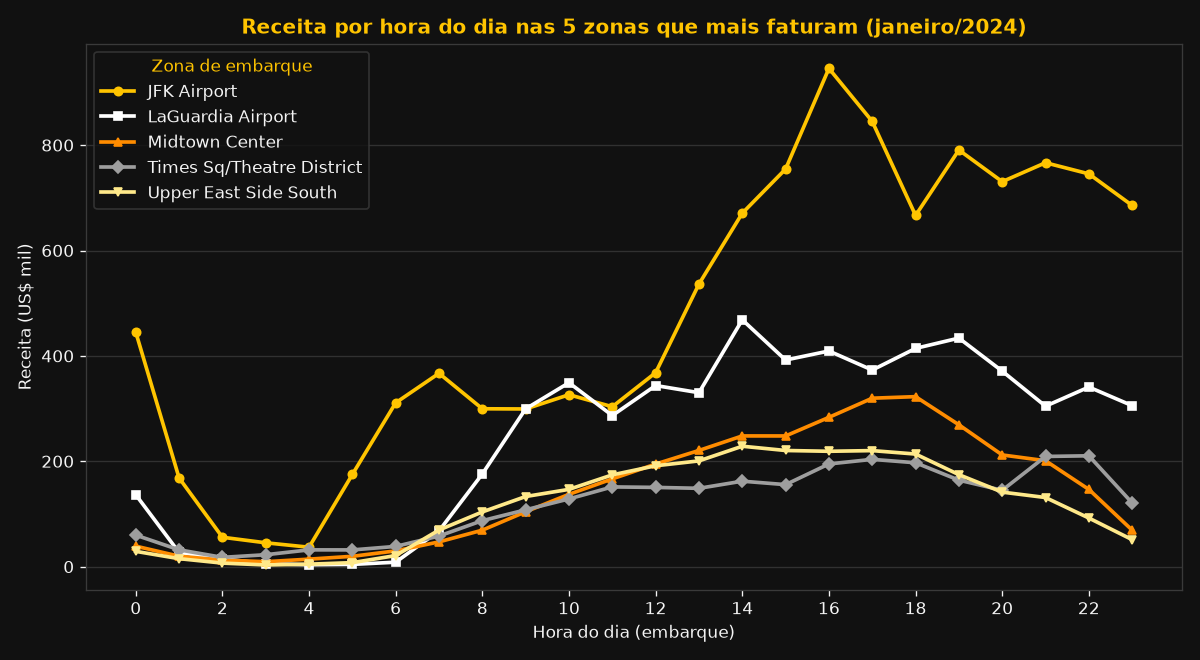

data\gold\graficos\eficiencia_bairro.png


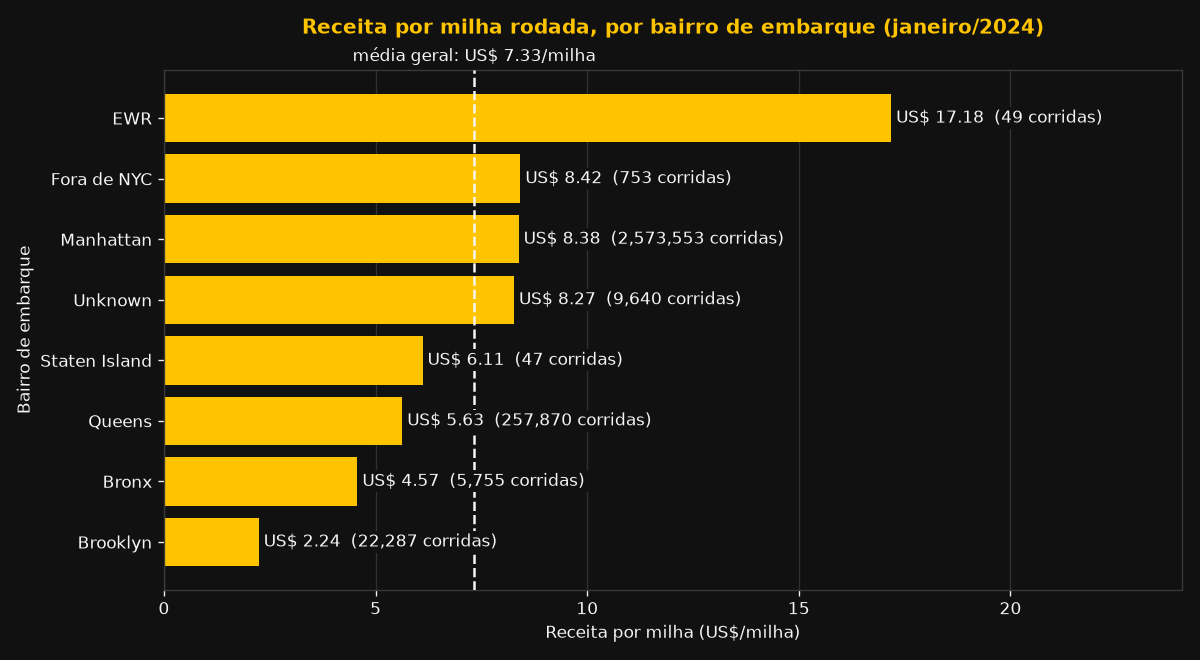

In [37]:
from IPython.display import Image

log_load = load(CONFIG["silver"], CONFIG["gold"])
print({k: v for k, v in log_load.items() if k in ("linhas_silver", "linhas_gold", "linhas_gold2", "graficos")})

pasta_gold = Path(CONFIG["gold"])
gold2 = pd.read_parquet(pasta_gold / CONFIG["gold2_parquet"])
print()
print("Gold 2 (eficiencia_bairro):")
display(gold2)

# Consulta SQL que responde à pergunta 2 e comparação com o pandas
con = sqlite3.connect(pasta_gold / CONFIG["gold_sqlite"])
sql = f"""
SELECT bairro, receita_total, qtd_corridas, corridas_com_distancia, milhas_totais, receita_por_milha, distancia_media, zonas_atendidas
FROM {CONFIG["gold2_tabela"]}
ORDER BY receita_por_milha DESC, bairro
"""
resultado_sql = pd.read_sql_query(sql, con)
con.close()
pd.testing.assert_frame_equal(resultado_sql, gold2, check_dtype=False, check_exact=False)
print("Gold 2: SQL == pandas  ->  OK")

# Reconciliação: a Gold 2 soma o mesmo que a Silver (nenhuma corrida perdida na agregação)
silver = pd.read_parquet(Path(CONFIG["silver"]) / CONFIG["silver_arquivo"], columns=["valor_total", "distancia_milhas"])
assert gold2["qtd_corridas"].sum() == len(silver)
assert abs(gold2["receita_total"].sum() - silver["valor_total"].sum()) < 0.5
print(f"Silver: {len(silver):,} corridas, US$ {silver['valor_total'].sum():,.2f}  |  "
      f"Gold 2: {gold2['qtd_corridas'].sum():,} corridas, US$ {gold2['receita_total'].sum():,.2f}  ->  OK")

for png in log_load["graficos"]:
    print(png)
    display(Image(filename=png))

In [38]:
# Prova final do Bloco 9: apagar a pasta data, rodar pipeline() uma vez e conferir as duas Golds e os dois gráficos
pasta_gold = Path(CONFIG["gold"])
pasta_graficos = pasta_gold / CONFIG["graficos"]
gold_1_antes = pd.read_parquet(pasta_gold / CONFIG["gold_parquet"])
gold_2_antes = pd.read_parquet(pasta_gold / CONFIG["gold2_parquet"])

zerar_data()
print("Pasta data existe?", Path(CONFIG["bronze"]).parent.exists())
_ = pipeline()

esperados = [pasta_gold / CONFIG["gold_parquet"], pasta_gold / CONFIG["gold2_parquet"], pasta_gold / CONFIG["gold_sqlite"],
             pasta_graficos / "receita_zona_hora.png", pasta_graficos / "eficiencia_bairro.png"]
for arq in esperados:
    print("OK       " if arq.exists() and arq.stat().st_size > 0 else "FALTANDO ", arq, f"({arq.stat().st_size / 1024:,.1f} KB)" if arq.exists() else "")
assert all(a.exists() and a.stat().st_size > 0 for a in esperados)

pd.testing.assert_frame_equal(gold_1_antes, pd.read_parquet(pasta_gold / CONFIG["gold_parquet"]))
pd.testing.assert_frame_equal(gold_2_antes, pd.read_parquet(pasta_gold / CONFIG["gold2_parquet"]))
print()
print("Gold 1 e Gold 2 reconstruídas do zero são idênticas às anteriores  ->  OK")

Pasta data existe? False


OK        data\gold\receita_zona_hora.parquet (93.8 KB)
OK        data\gold\eficiencia_bairro.parquet (5.8 KB)
OK        data\gold\gold.db (116,020.0 KB)
OK        data\gold\graficos\receita_zona_hora.png (98.8 KB)
OK        data\gold\graficos\eficiencia_bairro.png (59.2 KB)

Gold 1 e Gold 2 reconstruídas do zero são idênticas às anteriores  ->  OK


In [39]:
# P4: qual Gold é mais cara de recalcular? Mede só a agregação, a partir da Silver já em memória
silver_full = pd.read_parquet(Path(CONFIG["silver"]) / CONFIG["silver_arquivo"])
silver_full["dia"] = silver_full["data_embarque"].dt.day

def agregar_gold1(s):
    return (s.groupby(["id_zona_embarque", "bairro", "zona", "hora_embarque"], as_index=False)
              .agg(receita_total=("valor_total", "sum"), qtd_corridas=("valor_total", "size"),
                   ticket_medio=("valor_total", "mean"), dias_com_corrida=("dia", "nunique")))

custos = []
for nome, f in (("Gold 1 (zona x hora)", agregar_gold1), ("Gold 2 (bairro)", construir_gold_eficiencia_bairro)):
    tempos = []
    for _ in range(3):
        t0 = time.perf_counter(); r = f(silver_full); tempos.append(time.perf_counter() - t0)
    custos.append({"gold": nome, "linhas_resultado": len(r), "melhor_tempo_s": round(min(tempos), 3)})
display(pd.DataFrame(custos))

,gold,linhas_resultado,melhor_tempo_s
0,Gold 1 (zona x hora),5295,0.362
1,Gold 2 (bairro),8,0.192


### Visualização extra: mapa interativo da Gold 1

Mapa das zonas de embarque coloridas pela receita, com um controle deslizante para a **hora do dia** (a Gold 1 tem exatamente esse grão: zona x hora). Saída: `data/gold/graficos/mapa_receita_zona_hora.html` (abre no navegador, com zoom e informações ao passar o mouse).

- **Fonte nova:** a tabela de zonas do projeto não tem coordenadas, então o mapa usa o shapefile oficial da TLC (`taxi_zones.zip`, salvo em `fonte/`). Ele só serve para desenhar; a Gold continua saindo da Silver.
- **Fora do `pipeline()`:** o mapa é uma visualização opcional, não uma etapa da Bronze/Silver/Gold. Rodar o pipeline não depende dele.
- **Mapbox:** usamos o desenho de mapas do Plotly (`choropleth_map`) com o fundo claro gratuito da CARTO (legível no projetor), que não precisa de token. Com uma conta no Mapbox, dá para trocar o estilo em `CONFIG["mapa"]["estilo"]`.
- **Escala de cor:** vai até o percentil 95 da receita. Sem esse teto, a JFK (a zona que mais fatura) deixaria todas as outras na cor mais clara. A escala vai de amarelo claro (pouca receita) até preto (muita receita).

In [40]:
import io
import urllib.request
import zipfile

import plotly.express as px
import shapefile                      # pyshp
from pyproj import Transformer

CONFIG["mapa"] = {
    "zip_local": "fonte/taxi_zones.zip",
    "url": "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip",
    "html": "mapa_receita_zona_hora.html",
    "estilo": "carto-positron",        # fundo claro (melhor no projetor), gratuito e sem token. Com token do Mapbox, dá para usar um estilo deles
    "teto_percentil": 0.95,            # a escala de cor para no percentil 95 (a JFK sozinha estragaria o contraste)
}


def carregar_geojson_zonas():
    """Lê o shapefile oficial das zonas da TLC (a tabela de zonas do projeto não tem coordenadas)
    e devolve um GeoJSON em latitude/longitude, com o LocationID como id de cada zona."""
    zip_local = Path(CONFIG["mapa"]["zip_local"])
    if not zip_local.exists():
        print(f"Baixando {CONFIG['mapa']['url']} ...")
        urllib.request.urlretrieve(CONFIG["mapa"]["url"], zip_local)
    para_lonlat = Transformer.from_crs("EPSG:2263", "EPSG:4326", always_xy=True)   # pés de NY -> graus
    with zipfile.ZipFile(zip_local) as z:          # lê direto do zip, sem extrair nada em disco
        abrir = lambda ext: io.BytesIO(z.read(f"taxi_zones/taxi_zones.{ext}"))
        leitor = shapefile.Reader(shp=abrir("shp"), shx=abrir("shx"), dbf=abrir("dbf"))
    campos = [c[0] for c in leitor.fields[1:]]
    features = []
    for sr in leitor.shapeRecords():
        props = dict(zip(campos, sr.record))
        geom = sr.shape.__geo_interface__
        def conv(coords):
            if isinstance(coords[0], (int, float)):
                x, y = para_lonlat.transform(coords[0], coords[1])
                return [round(x, 4), round(y, 4)]      # ~10 m de precisão: sobra para um mapa da cidade
            return [conv(c) for c in coords]
        features.append({"type": "Feature", "id": int(props["LocationID"]),
                         "properties": {"LocationID": int(props["LocationID"])},
                         "geometry": {"type": geom["type"], "coordinates": conv(geom["coordinates"])}})
    return {"type": "FeatureCollection", "features": features}


def gerar_mapa(gold, destino):
    """Mapa interativo da Gold 1: receita por zona de embarque, com um controle deslizante de hora do dia."""
    geojson = carregar_geojson_zonas()
    zonas = sorted(f["id"] for f in geojson["features"])

    # Gold 1 tem uma linha por (zona, hora) só onde houve corrida: completa com zero para o mapa não "piscar"
    grade = pd.MultiIndex.from_product([zonas, range(24)], names=["id_zona_embarque", "hora_embarque"]).to_frame(index=False)
    g = grade.merge(gold, on=["id_zona_embarque", "hora_embarque"], how="left")
    nomes = gold.drop_duplicates("id_zona_embarque").set_index("id_zona_embarque")[["zona", "bairro"]]
    g["zona"] = g["id_zona_embarque"].map(nomes["zona"]).fillna("Sem corridas em jan/2024")
    g["bairro"] = g["id_zona_embarque"].map(nomes["bairro"]).fillna("-")
    g[["receita_total", "qtd_corridas", "ticket_medio"]] = g[["receita_total", "qtd_corridas", "ticket_medio"]].fillna(0)
    g["hora"] = g["hora_embarque"].map(lambda h: f"{h:02d}h")

    teto = float(g.loc[g["receita_total"] > 0, "receita_total"].quantile(CONFIG["mapa"]["teto_percentil"]))
    fig = px.choropleth_map(
        g, geojson=geojson, locations="id_zona_embarque", color="receita_total",
        animation_frame="hora", hover_name="zona",
        hover_data={"id_zona_embarque": False, "hora": False, "bairro": True, "receita_total": ":,.2f",
                    "qtd_corridas": ":,", "ticket_medio": ":,.2f"},
        labels={"receita_total": "Receita (US$)", "qtd_corridas": "Corridas", "ticket_medio": "Ticket médio (US$)",
                "bairro": "Bairro"},
        color_continuous_scale=[[0, "#FFF6C2"], [0.15, "#FFE066"], [0.4, "#FFC400"], [0.7, "#E07B00"], [1, "#111111"]],   # amarelo claro -> amarelo táxi -> laranja -> preto
        range_color=(0, teto), map_style=CONFIG["mapa"]["estilo"],
        center={"lat": 40.70, "lon": -73.90}, zoom=9.6, opacity=0.85)
    for quadro in fig.frames:          # o GeoJSON só precisa ir uma vez; repetir em cada hora deixaria o HTML enorme
        for trace in quadro.data:
            trace.geojson = None
    fig.update_layout(
        title=dict(text=f"Receita por zona de embarque e hora do dia (janeiro/2024) | escala até US$ {teto:,.0f}", font=dict(color="#111111", size=18)),
        paper_bgcolor="#FFFFFF", font=dict(color="#111111", size=14), margin=dict(l=0, r=0, t=50, b=0), height=720,
        coloraxis_colorbar=dict(title="Receita (US$)"))
    caminho = Path(destino) / CONFIG["graficos"] / CONFIG["mapa"]["html"]
    caminho.parent.mkdir(parents=True, exist_ok=True)
    fig.write_html(caminho, include_plotlyjs="cdn")
    return caminho, fig


Mapa salvo em: data\gold\graficos\mapa_receita_zona_hora.html (2.3 MB). Abra o arquivo no navegador.


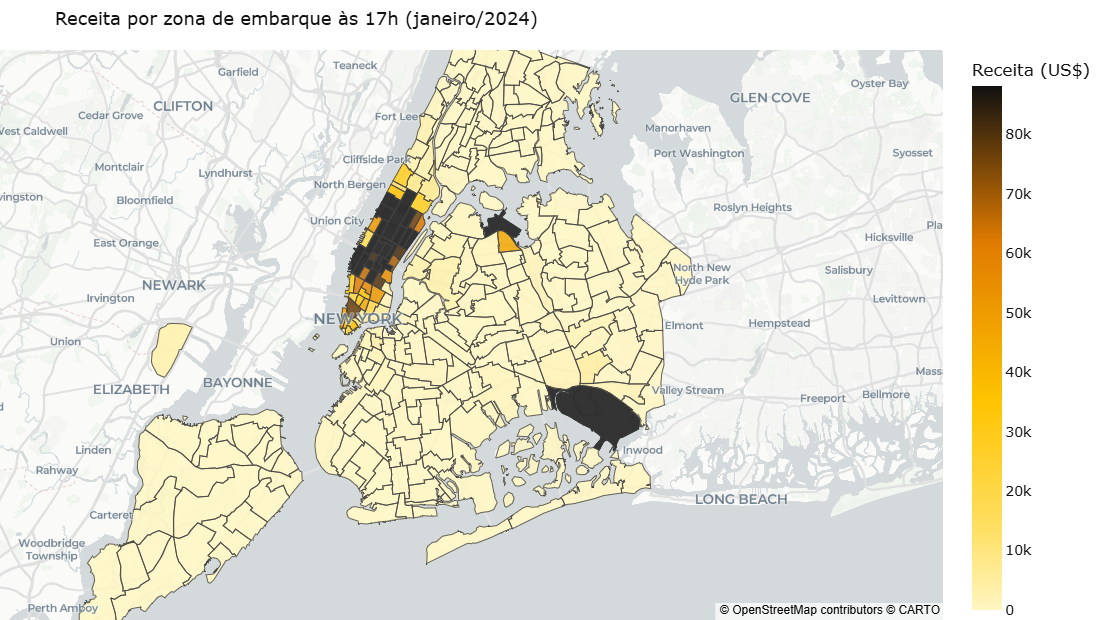

In [41]:
from IPython.display import Image

gold = pd.read_parquet(Path(CONFIG["gold"]) / CONFIG["gold_parquet"])
caminho_mapa, fig_mapa = gerar_mapa(gold, CONFIG["gold"])
print(f"Mapa salvo em: {caminho_mapa} ({caminho_mapa.stat().st_size / 1024 / 1024:.1f} MB). Abra o arquivo no navegador.")

# Prévia estática (17h, o pico de receita) para ficar visível aqui no notebook.
# Precisa do kaleido; se não der certo, o mapa HTML continua valendo.
try:
    quadro = next(f for f in fig_mapa.frames if f.name == "17h")
    fig_mapa.data[0].z = quadro.data[0].z
    fig_mapa.layout.sliders, fig_mapa.layout.updatemenus = [], []
    fig_mapa.update_layout(title_text="Receita por zona de embarque às 17h (janeiro/2024)", height=620)
    png = Path(CONFIG["gold"]) / CONFIG["graficos"] / "mapa_receita_17h.png"
    fig_mapa.write_image(png, width=1100, height=620)
    display(Image(filename=png))
except Exception as erro:
    print("Prévia estática não gerada (precisa do kaleido):", str(erro)[:120])

### Visualização extra: mapa 3D de torres (receita por zona)

Segunda versão do mapa, em 3D: cada zona de embarque vira um **bloco cuja altura e cor crescem com a receita**, como um dashboard de torres. Saída: `data/gold/graficos/mapa_torres_receita.html` (abre no navegador).

- **Como usar:** arraste para girar, use a roda para o zoom, o controle de hora (00h a 23h, ou *Janeiro inteiro*) e o botão *Tocar as 24 horas*. Ao passar o mouse aparece um resumo da zona; **ao clicar numa torre abre uma barra lateral** com o detalhe (receita do mês e % do total, corridas, ticket médio, posição no ranking, hora de maior receita e um gráfico da receita por hora; clicar numa barra do gráfico leva o mapa para aquela hora). Dá para abrir direto numa hora com `#h=16` no final do endereço.
- **Altura em raiz quadrada:** se a altura fosse proporcional à receita, as zonas dos aeroportos virariam arranha-céus e as outras ficariam achatadas. A raiz quadrada mantém a ordem (quem fatura mais é mais alto) e deixa o resto visível. A legenda do mapa avisa isso.
- **Mesmos dados:** usa a Gold 1 e o shapefile das zonas do mapa anterior. O shapefile não tem contorno para as zonas 264 (desconhecida) e 265 (fora de NYC): elas não aparecem no mapa, mas a porcentagem da receita no painel lateral usa o total da Gold (e a legenda mostra quanto ficou de fora). O mapa colorido continua valendo, os dois são complementares.
- **Precisa de internet** para carregar o fundo do mapa e as bibliotecas (deck.gl e MapLibre, por CDN). Fora do `pipeline()`, como o outro mapa.

In [ ]:
import json

CONFIG["mapa_torres"] = {
    "html": "mapa_torres_receita.html",
    "altura_max_m": 9000,              # altura da torre mais alta, em metros (só para a vista 3D ficar legível)
    "estilo_base": "https://basemaps.cartocdn.com/gl/positron-gl-style/style.json",   # fundo claro, sem token
}

MODELO_TORRES = r"""<!doctype html>
<html lang="pt-BR"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Torres de receita por zona | NYC Táxi amarelo, jan/2024</title>
<script src="https://unpkg.com/deck.gl@9.0.38/dist.min.js"></script>
<script src="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.js"></script>
<link href="https://unpkg.com/maplibre-gl@4.7.1/dist/maplibre-gl.css" rel="stylesheet">
<style>
  html, body, #mapa { margin: 0; height: 100%; font-family: system-ui, Segoe UI, Arial, sans-serif; }
  .painel { position: absolute; z-index: 5; background: rgba(255,255,255,.94); color: #111; border-radius: 8px;
            box-shadow: 0 2px 10px rgba(0,0,0,.3); padding: 14px 18px; }
  #titulo { top: 14px; left: 14px; max-width: 420px; border-left: 8px solid #FFC400; }
  #titulo h1 { font-size: 20px; margin: 0 0 4px; }
  #titulo p { margin: 0 0 10px; font-size: 14px; color: #333; }
  #hora { font-size: 28px; font-weight: 700; margin: 4px 0; }
  input[type=range] { width: 100%; accent-color: #FFC400; }
  button { font-size: 15px; padding: 6px 14px; border: 2px solid #111; background: #FFC400; color: #111;
           font-weight: 700; border-radius: 6px; cursor: pointer; margin-top: 6px; }
  #legenda { bottom: 24px; left: 14px; width: 330px; font-size: 13px; }
  #barra { height: 14px; border-radius: 4px; margin: 6px 0 4px;
           background: linear-gradient(90deg, #FFF6C2, #FFE066 15%, #FFC400 40%, #E07B00 70%, #111111); }
  #barra + div { display: flex; justify-content: space-between; }
  #detalhe { top: 130px; right: 14px; width: 340px; max-height: calc(100% - 160px); overflow: auto; display: none; border-top: 8px solid #FFC400; }
  #detalhe h2 { margin: 0 24px 0 0; font-size: 20px; }
  #detalhe .sub { color: #555; margin: 2px 0 8px; font-size: 14px; }
  #detalhe h3 { font-size: 14px; margin: 14px 0 4px; }
  .kpis { display: grid; grid-template-columns: 1fr 1fr; gap: 8px; margin: 8px 0; }
  .kpi { background: #FFF6C2; border-radius: 6px; padding: 8px 10px; }
  .kpi b { display: block; font-size: 17px; }
  .kpi span { font-size: 12px; color: #444; }
  #fechar { position: absolute; top: 4px; right: 8px; border: none; background: none; font-size: 26px; margin: 0; padding: 0 6px; }
  #detalhe svg text { font-size: 10px; fill: #333; }
  .dica { margin-top: 8px; font-size: 13px; color: #444; }
</style></head>
<body>
<div id="mapa"></div>
<div id="titulo" class="painel">
  <h1>Receita por zona de embarque</h1>
  <p>Cada bloco é uma zona de NYC: quanto mais alto e mais escuro, mais a zona faturou. Arraste o mapa para girar e use a roda para dar zoom.</p>
  <div id="hora"></div>
  <input id="slider" type="range" min="0" max="24" step="1" value="24">
  <button id="tocar">Tocar as 24 horas</button>
  <div class="dica">Passe o cursor numa torre para ver o resumo e <b>clique</b> para abrir o detalhe ao lado.</div>
</div>
<div id="detalhe" class="painel"></div>
<div id="legenda" class="painel">
  <b>Receita no período escolhido</b>
  <div id="barra"></div>
  <div><span>pouca</span><span>muita</span></div>
  <div style="margin-top:6px;color:#444">Altura e cor usam a raiz quadrada da receita: sem isso, as zonas dos aeroportos esconderiam todas as outras.</div>
  <div id="sem-contorno" style="margin-top:6px;color:#444"></div>
</div>
<script>
const GEO = __GEO__;
const DADOS = __DADOS__;
const MAXS = __MAXS__;               // maior receita de uma zona em cada visão (0 a 23 = hora, 24 = mês inteiro)
const ALTURA_MAX = __ALTURA__;
const PARADAS = [0, 0.15, 0.4, 0.7, 1];
const CORES = [[255,246,194],[255,224,102],[255,196,0],[224,123,0],[17,17,17]];

function escala(v, h) { return MAXS[h] > 0 ? Math.sqrt(Math.max(v, 0) / MAXS[h]) : 0; }
function cor(x) {
  for (let i = 1; i < PARADAS.length; i++) {
    if (x <= PARADAS[i]) {
      const f = (x - PARADAS[i-1]) / (PARADAS[i] - PARADAS[i-1]);
      return CORES[i-1].map((c, k) => Math.round(c + (CORES[i][k] - c) * f));
    }
  }
  return CORES[CORES.length - 1];
}
const usd = v => 'US$ ' + v.toLocaleString('en-US', {minimumFractionDigits: 2, maximumFractionDigits: 2});

let hora = 24;
let selecionada = null;                                   // LocationID da zona clicada
const ORDEM = Object.keys(DADOS).sort((a, b) => DADOS[b].rec[24] - DADOS[a].rec[24]);
const COM_RECEITA = ORDEM.filter(k => DADOS[k].rec[24] > 0).length;
const TOTAL_MES = __TOTAL__;                              // receita de TODAS as zonas da Gold (inclui as sem contorno)
const SEM_CONTORNO = TOTAL_MES - Object.values(DADOS).reduce((s, d) => s + d.rec[24], 0);
const hh = h => String(h).padStart(2, '0') + 'h';
function camada(h) {
  return new deck.GeoJsonLayer({
    id: 'torres', data: GEO, extruded: true, pickable: true, stroked: true,
    autoHighlight: true, highlightColor: [255, 196, 0, 255],
    getLineColor: f => f.properties.LocationID === selecionada ? [0, 0, 0, 255] : [70, 70, 70, 140],
    getLineWidth: f => f.properties.LocationID === selecionada ? 4 : 1,
    lineWidthUnits: 'pixels', lineWidthMinPixels: 0.5,
    getElevation: f => { const d = DADOS[f.properties.LocationID]; return d ? escala(d.rec[h], h) * ALTURA_MAX : 0; },
    getFillColor: f => { const d = DADOS[f.properties.LocationID]; return [...cor(d ? escala(d.rec[h], h) : 0), 240]; },
    updateTriggers: {getElevation: [h], getFillColor: [h], getLineColor: [selecionada], getLineWidth: [selecionada]},
    transitions: {getElevation: 600, getFillColor: 600},
    material: {ambient: 0.55, diffuse: 0.7, shininess: 24, specularColor: [255, 255, 255]}
  });
}

const mapa = new maplibregl.Map({
  container: 'mapa', style: __ESTILO__, center: [-73.90, 40.71], zoom: 10.3, pitch: 58, bearing: 62, maxPitch: 80
});
const overlay = new deck.MapboxOverlay({
  interleaved: false, layers: [camada(hora)],
  onClick: ({object}) => selecionar(object ? object.properties.LocationID : null),
  getTooltip: ({object}) => {
    if (!object) return null;
    const d = DADOS[object.properties.LocationID];
    if (!d) return null;
    return {html: '<b>' + d.zona + '</b><br>' + d.bairro + '<br>Receita: ' + usd(d.rec[hora]) +
                  '<br>Corridas: ' + d.n[hora].toLocaleString('en-US') +
                  '<br>Ticket médio: ' + usd(d.n[hora] ? d.rec[hora] / d.n[hora] : 0),
            style: {background: '#111', color: '#FFC400', fontSize: '14px', borderRadius: '6px'}};
  }
});
mapa.addControl(overlay);
mapa.addControl(new maplibregl.NavigationControl({visualizePitch: true}), 'bottom-right');

function graficoHoras(d) {
  const w = 300, h = 100, bw = w / 24, mx = Math.max(...d.rec.slice(0, 24), 1);
  let s = `<svg viewBox="0 0 ${w} ${h + 16}" width="100%">`;
  for (let i = 0; i < 24; i++) {
    const alt = d.rec[i] / mx * h;
    s += `<rect data-h="${i}" x="${i * bw + 1}" y="${h - alt}" width="${bw - 2}" height="${Math.max(alt, 0.5)}" ` +
         `fill="${i === hora ? '#111' : '#FFC400'}" style="cursor:pointer"><title>${hh(i)}: ${usd(d.rec[i])}</title></rect>`;
    if (i % 6 === 0) s += `<text x="${i * bw}" y="${h + 12}">${hh(i)}</text>`;
  }
  return s + '</svg>';
}

function detalhe() {
  const el = document.getElementById('detalhe');
  if (selecionada === null) { el.style.display = 'none'; return; }
  const d = DADOS[selecionada];
  const pos = ORDEM.indexOf(String(selecionada)) + 1;
  const pico = d.rec.slice(0, 24).indexOf(Math.max(...d.rec.slice(0, 24)));
  const ticket = (r, n) => usd(n ? r / n : 0);
  el.innerHTML =
    '<button id="fechar" title="Fechar">&times;</button>' +
    '<h2>' + d.zona + '</h2><div class="sub">' + d.bairro + ' &middot; zona ' + selecionada + '</div>' +
    (d.rec[24] > 0
      ? '<div class="kpis">' +
        '<div class="kpi"><b>' + usd(d.rec[24]) + '</b><span>receita em janeiro</span></div>' +
        '<div class="kpi"><b>' + (d.rec[24] / TOTAL_MES * 100).toFixed(2) + '%</b><span>da receita total</span></div>' +
        '<div class="kpi"><b>' + d.n[24].toLocaleString('en-US') + '</b><span>corridas</span></div>' +
        '<div class="kpi"><b>' + ticket(d.rec[24], d.n[24]) + '</b><span>ticket médio</span></div>' +
        '<div class="kpi"><b>#' + pos + ' de ' + COM_RECEITA + '</b><span>ranking de receita</span></div>' +
        '<div class="kpi"><b>' + hh(pico) + '</b><span>hora de maior receita</span></div></div>' +
        (hora < 24
          ? '<h3>Na hora selecionada (' + hh(hora) + ')</h3><div class="kpis">' +
            '<div class="kpi"><b>' + usd(d.rec[hora]) + '</b><span>receita</span></div>' +
            '<div class="kpi"><b>' + d.n[hora].toLocaleString('en-US') + '</b><span>corridas</span></div></div>'
          : '') +
        '<h3>Receita por hora do dia (clique numa barra para ver essa hora)</h3>' + graficoHoras(d)
      : '<p>Esta zona não teve corridas de embarque em janeiro de 2024.</p>');
  el.style.display = 'block';
}

function selecionar(id) {
  selecionada = id;
  detalhe();
  overlay.setProps({layers: [camada(hora)]});
}
document.getElementById('detalhe').addEventListener('click', e => {
  if (e.target.id === 'fechar') return selecionar(null);
  const barra = e.target.closest('rect[data-h]');
  if (barra) mostrar(+barra.dataset.h);
});

function mostrar(h) {
  hora = h;
  document.getElementById('hora').textContent = h === 24 ? 'Janeiro inteiro' : String(h).padStart(2, '0') + 'h às ' + String(h).padStart(2, '0') + 'h59';
  document.getElementById('slider').value = h;
  detalhe();
  overlay.setProps({layers: [camada(h)]});
}
document.getElementById('slider').addEventListener('input', e => mostrar(+e.target.value));
let timer = null;
document.getElementById('tocar').addEventListener('click', e => {
  if (timer) { clearInterval(timer); timer = null; e.target.textContent = 'Tocar as 24 horas'; return; }
  let h = 0; mostrar(h); e.target.textContent = 'Parar';
  timer = setInterval(() => { h = (h + 1) % 24; mostrar(h); }, 1500);
});
// abre direto numa hora com #h=16 no endereço (útil para compartilhar uma hora específica)
const h0 = (location.hash.match(/h=(\d+)/) || [])[1];
document.getElementById('sem-contorno').textContent = 'Fora do mapa (sem contorno no shapefile): zonas desconhecida e fora de NYC, ' + usd(SEM_CONTORNO) + ' (' + (SEM_CONTORNO / TOTAL_MES * 100).toFixed(2) + '% da receita).';
mostrar(h0 !== undefined && +h0 <= 24 ? +h0 : 24);
</script></body></html>
"""


def gerar_mapa_torres(gold, destino):
    """Mapa 3D da Gold 1: cada zona vira um bloco cuja altura e cor crescem com a receita.
    HTML único (deck.gl + MapLibre), com controle de hora do dia e uma visão do mês inteiro."""
    geojson = carregar_geojson_zonas()
    zonas = sorted(f["id"] for f in geojson["features"])

    g = gold.set_index(["id_zona_embarque", "hora_embarque"])
    nomes = gold.drop_duplicates("id_zona_embarque").set_index("id_zona_embarque")[["zona", "bairro"]]
    dados = {}
    for z in zonas:
        rec, n = [0.0] * 25, [0] * 25
        for h in range(24):
            if (z, h) in g.index:
                rec[h], n[h] = float(g.at[(z, h), "receita_total"]), int(g.at[(z, h), "qtd_corridas"])
        rec[24], n[24] = round(sum(rec[:24]), 2), sum(n[:24])         # visão "janeiro inteiro"
        dados[z] = {"zona": nomes["zona"].get(z, "Sem corridas em jan/2024"), "bairro": nomes["bairro"].get(z, "-"),
                    "rec": rec, "n": n}
    maxs = [max(d["rec"][h] for d in dados.values()) for h in range(25)]

    T = CONFIG["mapa_torres"]
    html = (MODELO_TORRES
            .replace("__GEO__", json.dumps(geojson, separators=(",", ":")))
            .replace("__DADOS__", json.dumps(dados, ensure_ascii=False, separators=(",", ":")))
            .replace("__MAXS__", json.dumps(maxs))
            .replace("__TOTAL__", repr(round(float(gold["receita_total"].sum()), 2)))
            .replace("__ALTURA__", str(T["altura_max_m"]))
            .replace("__ESTILO__", json.dumps(T["estilo_base"])))
    caminho = Path(destino) / CONFIG["graficos"] / T["html"]
    caminho.parent.mkdir(parents=True, exist_ok=True)
    caminho.write_text(html, encoding="utf-8")
    return caminho


In [43]:
caminho_torres = gerar_mapa_torres(gold, CONFIG["gold"])
print(f"Mapa 3D salvo em: {caminho_torres} ({caminho_torres.stat().st_size / 1024 / 1024:.1f} MB). Abra o arquivo no navegador.")

Mapa 3D salvo em: data\gold\graficos\mapa_torres_receita.html (1.9 MB). Abra o arquivo no navegador.


### Respostas do Bloco 9

**P1. A segunda pergunta exigiu algo que a Silver não tinha? Se sim, em qual camada a correção deve ser feita e por quê?**

A Silver tinha todas as colunas necessárias (`bairro`, `valor_total`, `distancia_milhas`), mas a pergunta expôs um problema que a Gold 1 nunca mostrou: **56.649 corridas têm distância 0** e foram mantidas na Silver (decisão do Bloco 4, porque têm receita real). Para "receita por milha" elas distorcem: a primeira versão da Gold 2 colocou o EWR com US$ 111/milha, mas 234 das suas 283 corridas tinham distância 0. Decidimos calcular a receita por milha só com corridas de distância maior que zero (no numerador e no denominador) e guardar `corridas_com_distancia` para deixar isso visível. A correção ficou na **Gold 2** e não na Silver porque a Silver alimenta várias saídas: tirar essas corridas dela reduziria a receita da Gold 1 e do modelo dimensional, que reconciliam com a Silver. `receita_total` e `qtd_corridas` da Gold 2 continuam somando tudo (2.926.603 corridas e US$ 80.322.496,42, igual à Silver). Ainda não sabemos se distância 0 é corrida cancelada ou erro do taxímetro; se o grupo concluir que é erro, o caminho certo é a Silver ganhar uma coluna marcadora (por exemplo `distancia_valida`) em vez de apagar as linhas.

**P2. Por que manter duas tabelas Gold em vez de uma única tabela com tudo?**

Porque os grãos são diferentes: a Gold 1 tem uma linha por zona e hora (5.295 linhas) e a Gold 2 uma linha por bairro (8 linhas). Uma tabela só teria que escolher um grão: ou repetiria as métricas do bairro em todas as linhas de zona e hora (e somar a coluna daria valores inflados), ou perderia o detalhe de zona e hora. Duas tabelas pequenas respondem cada pergunta com uma consulta simples, e uma mudança em uma delas (como a regra da distância) não mexe na outra.

**P3. O gráfico escolhido permite que alguém sem conhecimento técnico responda à pergunta em poucos segundos? O que mudaria para melhorá-lo?**

- **Gold 2 (barras):** sim para a pergunta "qual bairro rende mais por milha": as barras estão ordenadas, com o valor e o número de corridas em cada uma e a média geral tracejada (US$ 7,33/milha). O cuidado é que o topo é frágil: o EWR lidera com US$ 17,18/milha, mas só 49 corridas entram no cálculo (Staten Island, 47), enquanto Manhattan tem 2.573.553. Para melhorar, esconderíamos ou deixaríamos em cinza os bairros com poucas corridas.
- **Gold 1 (linhas):** o aeroporto JFK se destaca logo, com o pico às 16h (US$ 945 mil). Mas de madrugada as cinco linhas se juntam e ficam difíceis de separar. Para melhorar, poderíamos rotular direto na linha, em vez de legenda, ou um mapa de calor das 10 maiores zonas.

**P4. Qual das duas Golds é mais cara de recalcular e por quê?**

A Gold 1. Medindo só a agregação sobre a Silver já em memória (melhor de 3 execuções), ela levou cerca de 0,35 s contra cerca de 0,19 s da Gold 2. As duas leem as mesmas 2,9 milhões de linhas, mas a Gold 1 forma 5.295 grupos (zona x hora) e ainda conta dias distintos com `nunique` em cada um, enquanto a Gold 2 forma só 8 grupos. A diferença é pequena em valor absoluto; se a Silver crescesse (mais meses), ela cresceria mais rápido na Gold 1, que tem mais grupos. Os tempos variam de máquina para máquina.

# Bloco 10 | Parametrizar o Pipeline

# Bloco 11 | Documentação e reprodutibilidade